#**Análisis exploratorio de datos**
## Ciencia de datos en producción
### Entregable 2 (15%)

Datos con información de crédito, usuarios y pagos

#### **Table de Contenido**
0. [Configuración inicial](#scrollTo=asGkU5gFvPvJ)
1. [Carga de datos](#scrollTo=djw37BxawNjg)
2. [Exploración inicial de datos](#scrollTo=ojVP0F8t_2hB)
3. [Análisis univariable](#scrollTo=KbvBIiHgFHYV)
4. [Análisis bivariable](#scrollTo=q6sOSF04OZB_)
5. [Análisis multivariable](#scrollTo=5nA5Alq3i6kr)


#0. Configuración inicial

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##0.1.  Importación de librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

##0.2. Configuración del notebook

In [ ]:
# Ruta de archivo con datos crudos
ARCHIVO_DATOS = "/content/drive/MyDrive/DatosCrudos_Créditos_CDP/BD_creditos.csv"

# Configuración de visualización
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Estilo de gráficos
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

#1. Carga de datos

In [ ]:
df = pd.read_csv(ARCHIVO_DATOS, sep = ";")
df.head(10)

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,7/01/2025 14:40,1852560,12,32,Empleado,3500000,1000000,128650,"95,227787",795.00,0,2,0.00,0.00,NaN,NaN,0,0,0,"916,148.00",Creciente,1
1,4,9/01/2025 11:18,3181080,6,34,Empleado,5000000,2000000,441817,"95,227787",796.00,0,7,0.00,0.00,NaN,NaN,0,0,0,"4,473,774.00",Creciente,1
2,9,26/12/2024 18:52,670200,5,34,Independiente,5000000,2000000,108632,"95,227787",727.00,5,0,0.00,"274,561.00","274,561.00",NaN,2,0,1,NaN,NaN,1
3,9,4/12/2024 14:20,506807,2,25,Independiente,3000000,900000,199684,"95,227787",864.00,8,1,0.00,"27,564.00","27,564.00",NaN,1,0,6,NaN,NaN,1
4,4,30/04/2025 18:41,999780,10,26,Empleado,2000000,600000,92509,"95,227787",771.00,0,3,0.00,0.00,NaN,NaN,0,0,0,"61,000.00",Creciente,1
5,9,30/11/2024 11:38,465461,2,29,Independiente,3000000,1000000,183393,"86,830187",678.00,7,2,0.00,"4,158.00","4,158.00",NaN,0,0,4,NaN,NaN,1
6,9,4/12/2024 11:26,1084187,8,28,Independiente,3000000,1000000,112736,"86,830187",665.00,2,1,0.00,"6,182.00","6,182.00",NaN,1,0,0,NaN,NaN,1
7,4,27/03/2025 14:57,556680,6,30,Independiente,2000000,700000,82757,"18,451409",738.00,0,4,0.00,0.00,NaN,NaN,0,0,0,"955,038.00",Creciente,0
8,9,5/02/2025 17:31,4627577,10,33,Independiente,2000000,800000,392490,"47,613894",769.00,0,2,0.00,0.00,NaN,NaN,0,0,0,NaN,NaN,0
9,4,15/12/2024 11:23,2100000,8,26,Empleado,1200000,300000,237864,"28,340846",785.00,0,1,0.00,0.00,NaN,NaN,0,0,0,"1,193,037.00",Estable,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   tipo_credito                   10763 non-null  int64  
 1   fecha_prestamo                 10763 non-null  object 
 2   capital_prestado               10763 non-null  int64  
 3   plazo_meses                    10763 non-null  int64  
 4   edad_cliente                   10763 non-null  int64  
 5   tipo_laboral                   10763 non-null  object 
 6   salario_cliente                10763 non-null  int64  
 7   total_otros_prestamos          10763 non-null  int64  
 8   cuota_pactada                  10763 non-null  int64  
 9   puntaje                        10763 non-null  object 
 10  puntaje_datacredito            10757 non-null  float64
 11  cant_creditosvigentes          10763 non-null  int64  
 12  huella_consulta                10763 non-null 

#2. Exploración inicial de datos

## 2.1. Descripción general y caracterización
Variables que podrían ser eliminadas por un alto porcentaje de nulos:
- tendencia_ingresos
- promedio_ingresos_datacredito

In [ ]:
# Tipos de dato cargados por pandas
print("=" * 65)
print("Tipos de dato detectado")
print("=" * 65)
print(df.dtypes)
print(f"\nTotal: {df.shape[0]} filas × {df.shape[1]} columnas")

# Conteo de nulos por variable
print("\n" + "=" * 65)
print("Valores nulos por variable")
print("=" * 65)
nulos = df.isnull().sum()
nulos_pct = (nulos / len(df) * 100).round(2)
resumen_nulos = pd.DataFrame({
    'Nulos': nulos,
    '% del total': nulos_pct
}).sort_values('Nulos', ascending=False)

print(resumen_nulos[resumen_nulos['Nulos'] > 0])
print(f"\nVariables sin nulos: {(nulos == 0).sum()} de {len(nulos)}")

Tipos de dato detectado
tipo_credito                       int64
fecha_prestamo                    object
capital_prestado                   int64
plazo_meses                        int64
edad_cliente                       int64
tipo_laboral                      object
salario_cliente                    int64
total_otros_prestamos              int64
cuota_pactada                      int64
puntaje                           object
puntaje_datacredito              float64
cant_creditosvigentes              int64
huella_consulta                    int64
saldo_mora                       float64
saldo_total                      float64
saldo_principal                  float64
saldo_mora_codeudor              float64
creditos_sectorFinanciero          int64
creditos_sectorCooperativo         int64
creditos_sectorReal                int64
promedio_ingresos_datacredito    float64
tendencia_ingresos                object
Pago_atiempo                       int64
dtype: object

Total: 10763 filas

In [ ]:
# Clasificación de variables según tipo estadístico

clasificacion = pd.DataFrame({
    'Variable': df.columns,
    'Tipo pandas': df.dtypes.values,
    'Tipo estadístico': [
        'Categórica nominal',      # tipo_credito (códigos, no cantidades)
        'Temporal',                 # fecha_prestamo
        'Numérica continua',       # capital_prestado
        'Numérica discreta',       # plazo_meses
        'Numérica discreta',       # edad_cliente
        'Categórica nominal',      # tipo_laboral
        'Numérica continua',       # salario_cliente
        'Numérica continua',       # total_otros_prestamos
        'Numérica continua',       # cuota_pactada
        'Numérica continua',       # puntaje (score, pendiente corregir tipo)
        'Numérica continua',       # puntaje_datacredito
        'Numérica discreta',       # cant_creditosvigentes
        'Numérica discreta',       # huella_consulta
        'Numérica continua',       # saldo_mora
        'Numérica continua',       # saldo_total
        'Numérica continua',       # saldo_principal
        'Numérica continua',       # saldo_mora_codeudor
        'Numérica discreta',       # creditos_sectorFinanciero
        'Numérica discreta',       # creditos_sectorCooperativo
        'Numérica discreta',       # creditos_sectorReal
        'Numérica continua',       # promedio_ingresos_datacredito
        'Categórica ordinal',      # tendencia_ingresos
        'Categórica dicotómica'    # Pago_atiempo (variable objetivo)
    ],
    'Subtipo': [
        'Politómica (6 categorías)',   # tipo_credito
        'Fecha y hora',                # fecha_prestamo
        'Monto en COP',                # capital_prestado
        'Conteo (meses)',              # plazo_meses
        'Conteo (años)',               # edad_cliente
        'Dicotómica (2 categorías)',   # tipo_laboral
        'Monto en COP',                # salario_cliente
        'Monto en COP',                # total_otros_prestamos
        'Monto en COP',                # cuota_pactada
        'Score / porcentaje',          # puntaje
        'Score (0-1000)',              # puntaje_datacredito
        'Conteo',                      # cant_creditosvigentes
        'Conteo',                      # huella_consulta
        'Monto en COP',                # saldo_mora
        'Monto en COP',                # saldo_total
        'Monto en COP',                # saldo_principal
        'Monto en COP',                # saldo_mora_codeudor
        'Conteo',                      # creditos_sectorFinanciero
        'Conteo',                      # creditos_sectorCooperativo
        'Conteo',                      # creditos_sectorReal
        'Monto en COP',                # promedio_ingresos_datacredito
        'Ordinal (3 categorías)',      # tendencia_ingresos
        'Binaria (0/1) - TARGET'       # Pago_atiempo
    ],
    'Requiere corrección': [
        'Sí - convertir a categórica',
        'Sí - convertir a datetime',
        'No',
        'No',
        'No',
        'No - convertir a category',
        'No',
        'No',
        'No',
        'Sí - convertir a numérica (coma decimal)',
        'No',
        'No',
        'No',
        'No',
        'No',
        'No',
        'No',
        'No',
        'No',
        'No',
        'No',
        'Sí - tiene valores numéricos infiltrados',
        'No - convertir a category'
    ]
})

clasificacion

,Variable,Tipo pandas,Tipo estadístico,Subtipo,Requiere corrección
0,tipo_credito,int64,Categórica nominal,Politómica (6 categorías),Sí - convertir a categórica
1,fecha_prestamo,object,Temporal,Fecha y hora,Sí - convertir a datetime
2,capital_prestado,int64,Numérica continua,Monto en COP,No
3,plazo_meses,int64,Numérica discreta,Conteo (meses),No
4,edad_cliente,int64,Numérica discreta,Conteo (años),No
5,tipo_laboral,object,Categórica nominal,Dicotómica (2 categorías),No - convertir a category
6,salario_cliente,int64,Numérica continua,Monto en COP,No
7,total_otros_prestamos,int64,Numérica continua,Monto en COP,No
8,cuota_pactada,int64,Numérica continua,Monto en COP,No
9,puntaje,object,Numérica continua,Score / porcentaje,Sí - convertir a numérica (coma decimal)


## 2.2. Unificación de la representación de nulos

In [ ]:
# Unificación de la representación de nulos

# Lista de posibles representaciones de nulos
nulos_disfrazados = [
    '', ' ', 'NA', 'N/A', 'n/a', 'Na', 'na',
    'NULL', 'null', 'Null',
    'NaN', 'nan', 'NAN',
    'None', 'none', 'NONE',
    'No aplica', 'NO APLICA', 'no aplica',
    'No disponible', 'NO DISPONIBLE',
    'Sin dato', 'SIN DATO', 'sin dato',
    'Sin información', 'SIN INFORMACIÓN',
    '-', '--', '?', '.',
    'No registra', 'NO REGISTRA',
    'Desconocido', 'DESCONOCIDO',
    'Vacío', 'VACÍO', 'vacio'
]

# --- Detección ---
print("=" * 65)
print("BÚSQUEDA DE POSIBLES NULOS EN VARIABLES TIPO OBJECT")
print("=" * 65)
cols_object = df.select_dtypes(include='object').columns
total_convertidos = 0

for col in cols_object:
    mask_lista = df[col].isin(nulos_disfrazados)
    mask_vacias = df[col].str.strip() == ''
    mask_total = mask_lista | mask_vacias
    encontrados = mask_total.sum()

    if encontrados > 0:
        print(f"\n  {col}: {encontrados} valores convertidos a NaN")
        detalle = df[col][mask_total]
        print(f"    Valores encontrados: {detalle.value_counts().to_dict()}")
        df.loc[mask_total, col] = np.nan
        total_convertidos += encontrados

if total_convertidos == 0:
    print("  No se encontraron nulos disfrazados. No se requiere conversión.")

# --- Documentación de casos pendientes de investigación ---
print("\n" + "=" * 65)
print("CASOS PENDIENTES DE REVISIÓN (no convertidos)")
print("=" * 65)

print("\n  1. tendencia_ingresos: valores numéricos infiltrados")
print("     → No son nulos, son errores de tipo.")
print("     → Se tratarán en el paso 2.4 (conversión de tipos).")

print("\n  2. salario_cliente: valores en cero")
print("     → Requiere análisis antes de decidir si son nulos.")
print("     → Se investigará en el paso 3.1 (análisis univariable).")

print("\n  3. promedio_ingresos_datacredito: valores en cero")
print("     → Requiere análisis antes de decidir si son nulos.")
print("     → Se investigará en el paso 3.1 (análisis univariable).")

# --- Resumen de nulos después de unificación ---
print("\n" + "=" * 65)
print("RESUMEN DE NULOS DESPUÉS DE UNIFICACIÓN")
print("=" * 65)
nulos_post = df.isnull().sum()
nulos_post = nulos_post[nulos_post > 0].sort_values(ascending=False)
nulos_post_pct = (nulos_post / len(df) * 100).round(2)
print(pd.DataFrame({
    'Nulos': nulos_post,
    '% del total': nulos_post_pct
}))

BÚSQUEDA DE POSIBLES NULOS EN VARIABLES TIPO OBJECT
  No se encontraron nulos disfrazados. No se requiere conversión.

CASOS PENDIENTES DE REVISIÓN (no convertidos)

  1. tendencia_ingresos: valores numéricos infiltrados
     → No son nulos, son errores de tipo.
     → Se tratarán en el paso 2.4 (conversión de tipos).

  2. salario_cliente: valores en cero
     → Requiere análisis antes de decidir si son nulos.
     → Se investigará en el paso 3.1 (análisis univariable).

  3. promedio_ingresos_datacredito: valores en cero
     → Requiere análisis antes de decidir si son nulos.
     → Se investigará en el paso 3.1 (análisis univariable).

RESUMEN DE NULOS DESPUÉS DE UNIFICACIÓN
                               Nulos  % del total
tendencia_ingresos              2932        27.24
promedio_ingresos_datacredito   2930        27.22
saldo_mora_codeudor              590         5.48
saldo_principal                  405         3.76
saldo_mora                       156         1.45
saldo_total  

##2.3. Eliminación de variables irrelevantes

In [ ]:
# No hay variables irrelevantes (Ids, nombres, correos, teléfonos)

##2.4. Conversión al tipo correcto de dato

In [ ]:
# Conversión de tipos de dato

print("TIPOS ANTES DE LA CONVERSIÓN:")
print("=" * 65)
print(df[['puntaje', 'fecha_prestamo', 'tipo_credito',
          'tipo_laboral', 'tendencia_ingresos', 'Pago_atiempo']].dtypes)

# 1. puntaje: texto con coma decimal a numérica
df['puntaje'] = pd.to_numeric(
    df['puntaje'].str.replace(',', '.'), errors='coerce'
)

# 2. fecha_prestamo: texto a datetime
df['fecha_prestamo'] = pd.to_datetime(
    df['fecha_prestamo'], dayfirst=True, errors='coerce'
)

# 3. tipo_credito: entero a categórica
df['tipo_credito'] = df['tipo_credito'].astype('category')

# 4. tipo_laboral: texto a categórica
df['tipo_laboral'] = df['tipo_laboral'].astype('category')

# 5. tendencia_ingresos: limpiar infiltrados + convertir a categórica
categorias_validas = ['Creciente', 'Decreciente', 'Estable']
infiltrados = (
    df['tendencia_ingresos'].notna() &
    ~df['tendencia_ingresos'].isin(categorias_validas)
)
print(f"\ntendencia_ingresos: {infiltrados.sum()} valores numéricos "
      f"infiltrados convertidos a NaN")
df.loc[infiltrados, 'tendencia_ingresos'] = np.nan # Valores infiltrados como nulos
df['tendencia_ingresos'] = df['tendencia_ingresos'].astype('category') # Corrección a tipo category

# 6. Pago_atiempo: entero a categórica
df['Pago_atiempo'] = df['Pago_atiempo'].astype('category')

# --- Verificación ---
print("\n" + "=" * 65)
print("TIPOS DESPUÉS DE LA CONVERSIÓN:")
print("=" * 65)
print(df[['puntaje', 'fecha_prestamo', 'tipo_credito',
          'tipo_laboral', 'tendencia_ingresos', 'Pago_atiempo']].dtypes)

# Verificar que no se generaron nulos inesperados en puntaje
nulos_puntaje = df['puntaje'].isna().sum()
print(f"\nNulos generados en puntaje tras conversión: {nulos_puntaje}")

# Verificar que no se generaron nulos inesperados en fecha_prestamo
nulos_fecha = df['fecha_prestamo'].isna().sum()
print(f"Nulos generados en fecha_prestamo tras conversión: {nulos_fecha}")

# Verificar nulos actualizados en tendencia_ingresos
nulos_tend = df['tendencia_ingresos'].isna().sum()
print(f"Nulos totales en tendencia_ingresos: {nulos_tend} "
      f"(eran 2932 + 58 infiltrados = 2990 esperados)")

TIPOS ANTES DE LA CONVERSIÓN:
puntaje               object
fecha_prestamo        object
tipo_credito           int64
tipo_laboral          object
tendencia_ingresos    object
Pago_atiempo           int64
dtype: object

tendencia_ingresos: 58 valores numéricos infiltrados convertidos a NaN

TIPOS DESPUÉS DE LA CONVERSIÓN:
puntaje                      float64
fecha_prestamo        datetime64[ns]
tipo_credito                category
tipo_laboral                category
tendencia_ingresos          category
Pago_atiempo                category
dtype: object

Nulos generados en puntaje tras conversión: 0
Nulos generados en fecha_prestamo tras conversión: 0
Nulos totales en tendencia_ingresos: 2990 (eran 2932 + 58 infiltrados = 2990 esperados)


# 3. Exploración de datos y descripción (EDA)

##3.1. Análisis univariable

### 3.1.1. Resumen estadístico
- **salario_cliente:** Skewness de 43.8 y kurtosis de 2,211. Valores muy altos que pueden indicar outliers que distorsionan la distribución.
- **total_otros_prestamos:** Mismo patrón, skewness de 38.5, kurtosis de 1,719. Mediana de 1,000,000 pero máximo de 6,787 millones.
- **saldo_mora:** Skewness de 40.6, kurtosis de 1,845. La mediana, el percentil 25 y el percentil 75 son todos $0. Más del 75% de quienes solicitan créditos no tienen mora reportada y quienes si la tienen tienen saldos altos.
- **saldo_mora_codeudor:** Kurtosis de 9,279, la más alta del dataset. La inmensa mayoría tiene 0 y unos poquísimos casos tienen mora del codeudor.
- **puntaje:** La mediana, el percentil 25 y el percentil 75 son todos iguales (95.227787). El IQR es 0. Esto confirma que el 87% del dataset tiene el mismo valor. Además, tiene skewness de -4.87 (cola fuerte hacia la izquierda), lo que significa que la minoría que tiene valores diferentes tiende a tener valores mucho más bajos. Esto puede indicar que es un score interno donde el valor 95.23 es un "techo" o valor por defecto asignado a clientes aprobados con perfil estándar.



In [ ]:
desc = df.describe().T

# Métricas adicionales que
desc['rango'] = desc['max'] - desc['min']
desc['IQR'] = desc['75%'] - desc['25%']
desc['skewness'] = df.select_dtypes(include='number').skew()
desc['kurtosis'] = df.select_dtypes(include='number').kurtosis()

desc

,count,mean,min,25%,50%,75%,max,std,rango,IQR,skewness,kurtosis
fecha_prestamo,10763,2025-04-16 23:05:32.851435520,2024-11-26 09:17:00,2025-01-20 17:32:30,2025-03-27 16:23:00,2025-06-16 13:27:30,2026-04-26 18:43:00,NaN,516 days 09:26:00,146 days 19:55:00,NaN,NaN
capital_prestado,"10,763.00","2,434,315.00","360,000.00","1,224,831.00","1,921,920.00","3,084,840.00","41,444,153.00","1,909,642.76","41,084,153.00","1,860,009.00",3.72,35.32
plazo_meses,"10,763.00",10.58,2.00,6.00,10.00,12.00,90.00,6.63,88.00,6.00,2.46,7.78
edad_cliente,"10,763.00",43.95,19.00,33.00,42.00,53.00,123.00,15.06,104.00,20.00,1.93,7.87
salario_cliente,"10,763.00","17,216,431.46",0.00,"2,000,000.00","3,000,000.00","4,875,808.00","22,000,000,000.00","355,476,717.60","22,000,000,000.00","2,875,808.00",43.78,"2,211.23"
total_otros_prestamos,"10,763.00","6,238,869.65",0.00,"500,000.00","1,000,000.00","2,000,000.00","6,787,675,263.00","118,418,316.94","6,787,675,263.00","1,500,000.00",38.46,"1,719.28"
cuota_pactada,"10,763.00","243,617.41","23,944.00","121,041.50","182,863.00","287,833.50","3,816,752.00","210,493.69","3,792,808.00","166,792.00",3.79,26.65
puntaje,"10,763.00",91.17,-38.01,95.23,95.23,95.23,95.23,16.47,133.24,0.00,-4.87,24.08
puntaje_datacredito,"10,757.00",780.79,-7.00,757.00,791.00,825.00,999.00,104.88,"1,006.00",68.00,-5.64,39.44
cant_creditosvigentes,"10,763.00",5.73,0.00,3.00,5.00,8.00,62.00,3.98,62.00,5.00,1.80,8.62


### 3.1.1. Resumen estadístico - Variables categóricas
- **tipo_credito:**  concentración en dos líneas. El 72% del dataset es tipo 4 y el 27% es tipo 9. Los otros tipos (6, 7, 10, 68) representan apenas el 1.3% combinado. Esto significa que el análisis será confiable para los tipos 4 y 9 pero no tendremos suficientes datos para sacar conclusiones confiables sobre los demás. El 68 puede ser un error.
- **tipo_laboral:** 63% empleados vs. 37% independientes.
- **tendencia_ingresos:** sesgo hacia ingresos crecientes. De los registros con dato válido, el 49% tiene ingresos crecientes, 12% decrecientes y 11% estables. El 28% son nulos.
- **Pago_atiempo:** 95.25% pagaron vs. 4.75% incumplieron. Desbalance severo.

In [ ]:
cols_cat = df.select_dtypes(include='category').columns

for col in cols_cat:
    print("=" * 55)
    print(f"Variable: {col}")
    print("=" * 55)
    conteo = df[col].value_counts(dropna=False)
    pct = df[col].value_counts(dropna=False, normalize=True) * 100
    resumen = pd.DataFrame({
        'Frecuencia': conteo,
        '% del total': pct.round(2)
    })
    print(resumen)
    print()

Variable: tipo_credito
              Frecuencia  % del total
tipo_credito                         
4                   7747        71.98
9                   2876        26.72
10                   116         1.08
6                     21         0.20
7                      2         0.02
68                     1         0.01

Variable: tipo_laboral
               Frecuencia  % del total
tipo_laboral                          
Empleado             6754        62.75
Independiente        4009        37.25

Variable: tendencia_ingresos
                    Frecuencia  % del total
tendencia_ingresos                         
Creciente                 5294        49.19
NaN                       2990        27.78
Decreciente               1291        11.99
Estable                   1188        11.04

Variable: Pago_atiempo
              Frecuencia  % del total
Pago_atiempo                         
1                  10252        95.25
0                    511         4.75



###3.1.3. Visualización univariable - Variables del crédito
Capital prestado: Sesgo a la derecha: la mayoría de los créditos son de montos bajos (entre 0.5M y 3M) con una cola larga hacia valores altos.

Plazo meses: Picos se observan en valores como 6, 10, 12, 24 y 36 meses (valores usuales que ofrecen los bancos)

Cuota: Sesgada a la derecha. Mayoría de cuotas por debajo de 500.000.


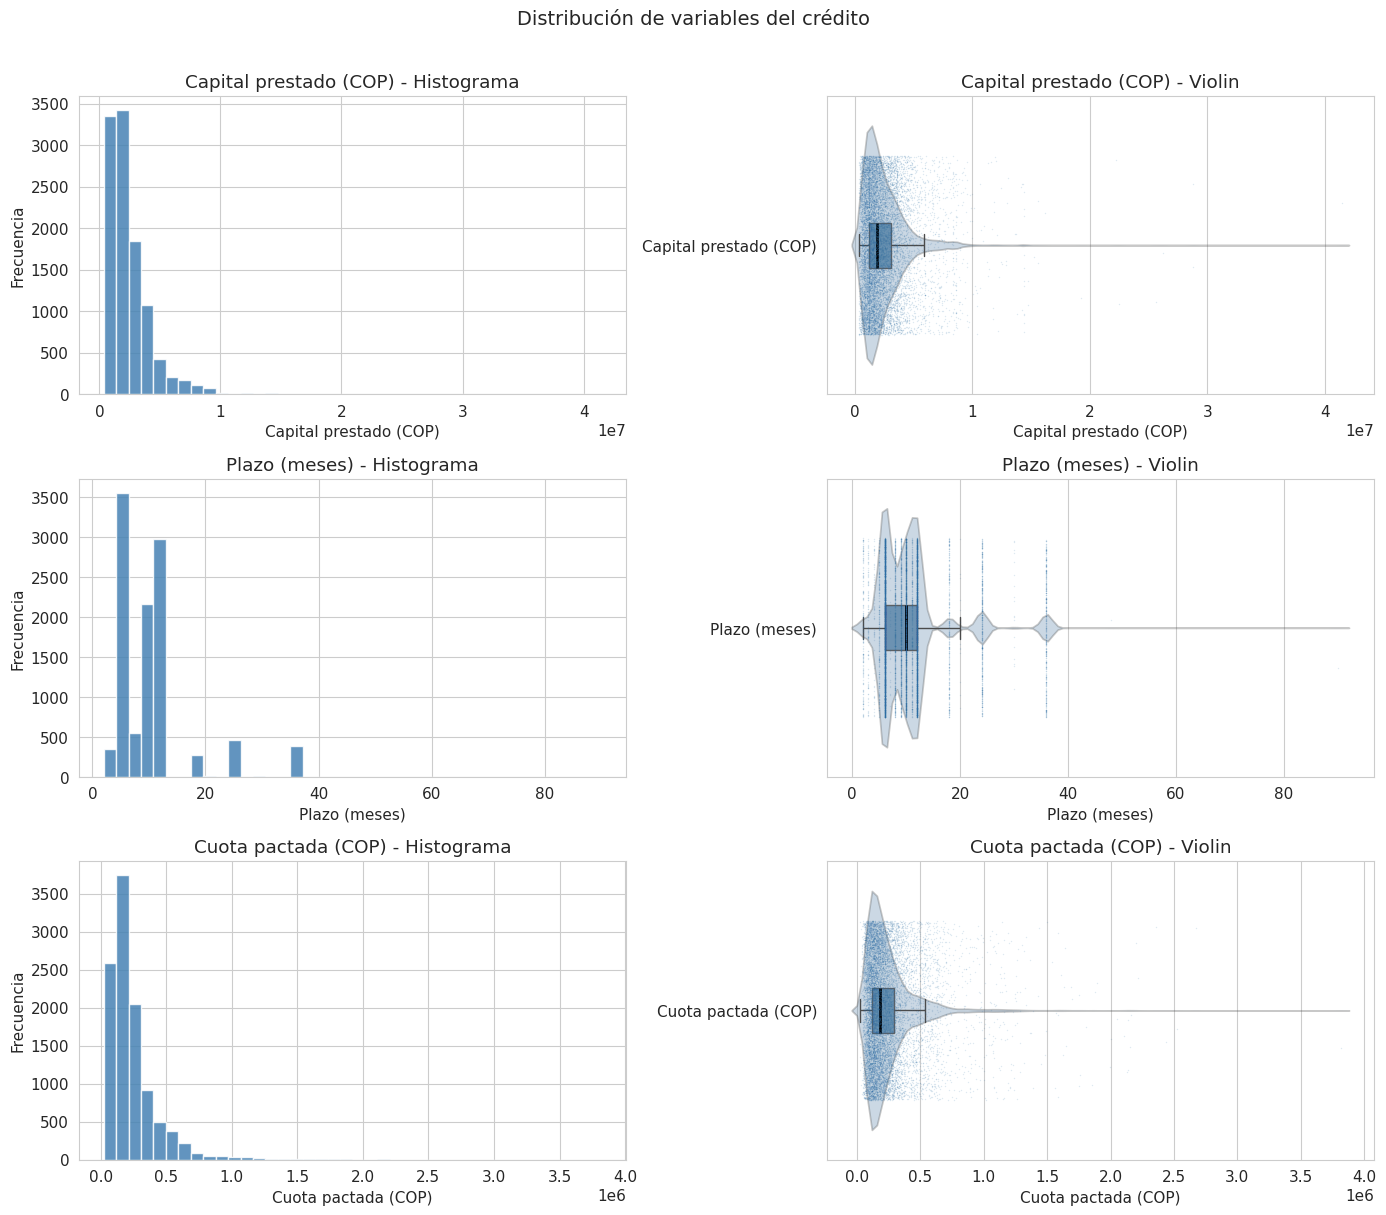

In [ ]:
vars_credito = ['capital_prestado', 'plazo_meses', 'cuota_pactada']
titulos = ['Capital prestado (COP)', 'Plazo (meses)', 'Cuota pactada (COP)']

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
fig.suptitle('Distribución de variables del crédito', fontsize=14, y=1.01)

for i, (var, titulo) in enumerate(zip(vars_credito, titulos)):
    datos = df[[var]].dropna()
    datos['grupo'] = titulo

    # Histograma (izquierda)
    axes[i, 0].hist(df[var].dropna(), bins=40, color='steelblue',
                    edgecolor='white', alpha=0.85)
    axes[i, 0].set_title(f'{titulo} - Histograma')
    axes[i, 0].set_xlabel(titulo)
    axes[i, 0].set_ylabel('Frecuencia')

    # Violin híbrido (derecha)
    sns.violinplot(data=datos, y='grupo', x=var,
                   color='steelblue', inner=None,
                   alpha=0.3, ax=axes[i, 1])

    sns.boxplot(data=datos, y='grupo', x=var,
                width=0.15, color='steelblue',
                showfliers=False,
                boxprops=dict(alpha=0.8),
                medianprops=dict(color='black', linewidth=2),
                ax=axes[i, 1])

    sns.stripplot(data=datos, y='grupo', x=var,
                  color='#2b6ca3', size=1, alpha=0.15,
                  jitter=0.3, ax=axes[i, 1])

    axes[i, 1].set_title(f'{titulo} - Violin')
    axes[i, 1].set_xlabel(titulo)
    axes[i, 1].set_ylabel('')

plt.tight_layout()
plt.show()

### 3.1.4. Visualización univariable - Perfil del cliente

Edad del cliente: Distribución normal si se omiten los outliers de 123 años. Concentración entre 25 y 65 años.

Salario y total otros préstamos: Los outliers alteran la visualización por ser tan extremos



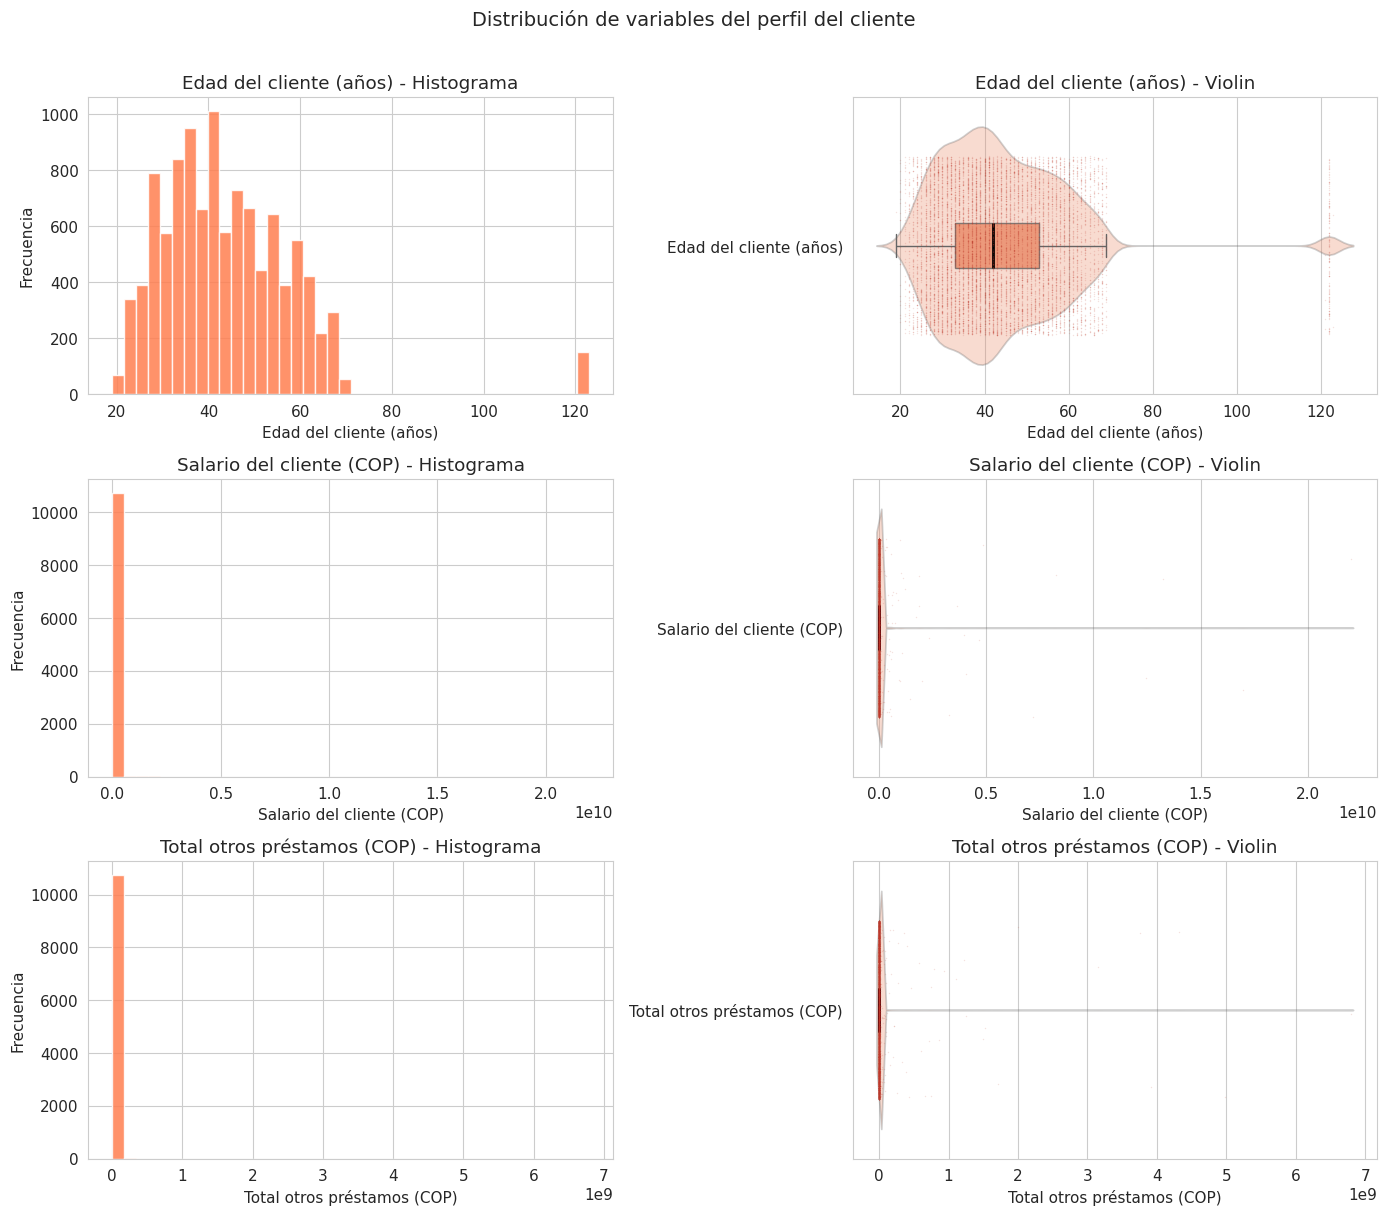

In [ ]:
# 3.1.4. Visualización univariable - Perfil del cliente

vars_cliente = ['edad_cliente', 'salario_cliente',
                'total_otros_prestamos']
titulos = ['Edad del cliente (años)', 'Salario del cliente (COP)',
           'Total otros préstamos (COP)']

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
fig.suptitle('Distribución de variables del perfil del cliente',
             fontsize=14, y=1.01)

for i, (var, titulo) in enumerate(zip(vars_cliente, titulos)):
    datos = df[[var]].dropna()
    datos['grupo'] = titulo

    # Histograma (izquierda)
    axes[i, 0].hist(df[var].dropna(), bins=40, color='coral',
                    edgecolor='white', alpha=0.85)
    axes[i, 0].set_title(f'{titulo} - Histograma')
    axes[i, 0].set_xlabel(titulo)
    axes[i, 0].set_ylabel('Frecuencia')

    # Violin híbrido (derecha)
    sns.violinplot(data=datos, y='grupo', x=var,
                   color='coral', inner=None,
                   alpha=0.3, ax=axes[i, 1])

    sns.boxplot(data=datos, y='grupo', x=var,
                width=0.15, color='coral',
                showfliers=False,
                boxprops=dict(alpha=0.8),
                medianprops=dict(color='black', linewidth=2),
                ax=axes[i, 1])

    sns.stripplot(data=datos, y='grupo', x=var,
                  color='#c0392b', size=1, alpha=0.15,
                  jitter=0.3, ax=axes[i, 1])

    axes[i, 1].set_title(f'{titulo} - Violin')
    axes[i, 1].set_xlabel(titulo)
    axes[i, 1].set_ylabel('')

plt.tight_layout()
plt.show()

###3.1.5. Salario y otros préstamos - vista sin outliers extremos
(Solo para visualización, los datos originales NO se modifican)

Ambas variables tienen un sesgos a la derecha.

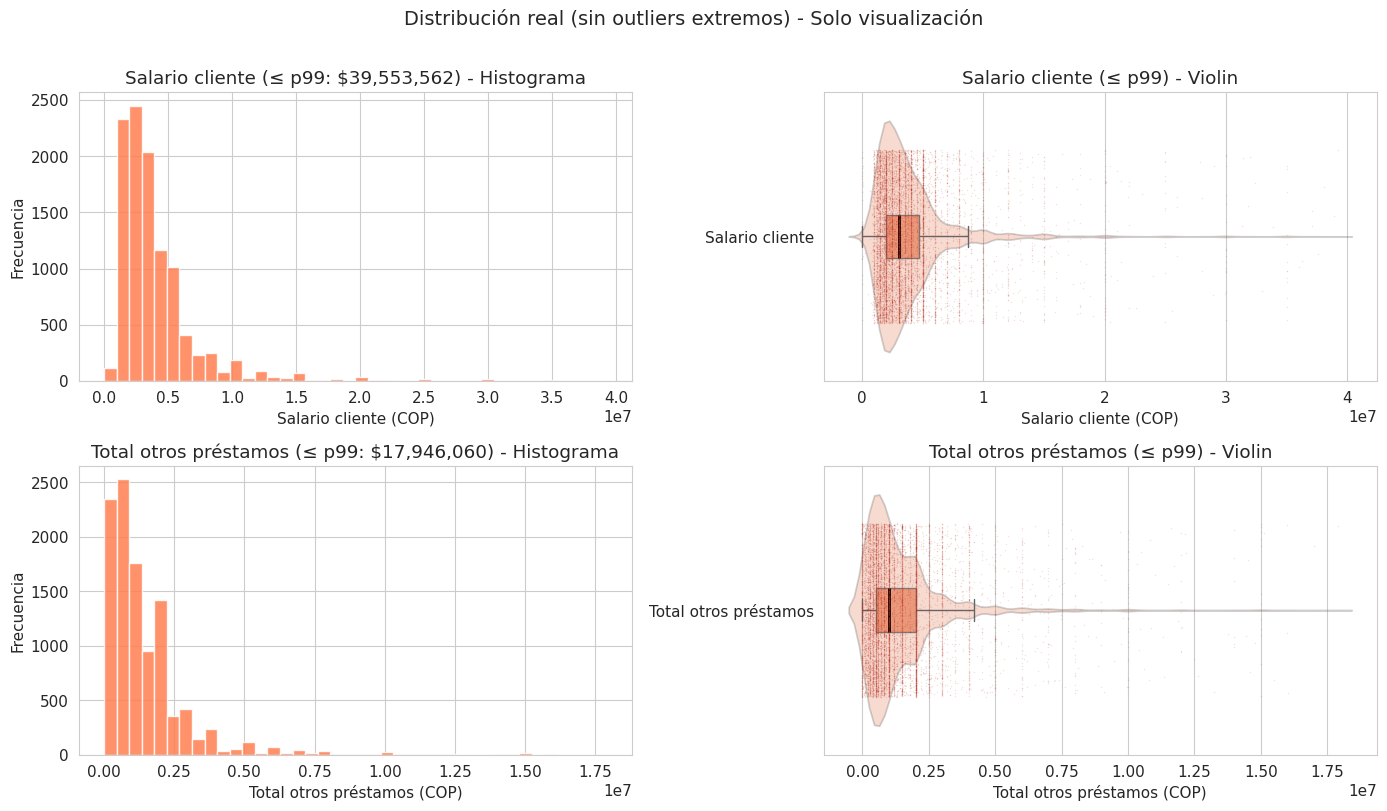

Salario: se excluyeron 108 registros por encima de $39,553,562
Otros préstamos: se excluyeron 108 registros por encima de $17,946,060


In [ ]:
# 3.1.5. Salario y otros préstamos - vista sin outliers extremos
# (Solo para visualización, los datos originales NO se modifican)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Distribución real (sin outliers extremos) - Solo visualización',
             fontsize=14, y=1.01)

vars_filt = ['salario_cliente', 'total_otros_prestamos']
titulos_filt = ['Salario cliente', 'Total otros préstamos']

for i, (var, titulo) in enumerate(zip(vars_filt, titulos_filt)):
    p99 = df[var].quantile(0.99)
    datos = df.loc[df[var] <= p99, [var]].dropna()
    datos['grupo'] = titulo

    # Histograma (izquierda)
    axes[i, 0].hist(datos[var], bins=40, color='coral',
                    edgecolor='white', alpha=0.85)
    axes[i, 0].set_title(f'{titulo} (≤ p99: ${p99:,.0f}) - Histograma')
    axes[i, 0].set_xlabel(f'{titulo} (COP)')
    axes[i, 0].set_ylabel('Frecuencia')

    # Violin híbrido (derecha)
    sns.violinplot(data=datos, y='grupo', x=var,
                   color='coral', inner=None,
                   alpha=0.3, ax=axes[i, 1])

    sns.boxplot(data=datos, y='grupo', x=var,
                width=0.15, color='coral',
                showfliers=False,
                boxprops=dict(alpha=0.8),
                medianprops=dict(color='black', linewidth=2),
                ax=axes[i, 1])

    sns.stripplot(data=datos, y='grupo', x=var,
                  color='#c0392b', size=1, alpha=0.15,
                  jitter=0.3, ax=axes[i, 1])

    axes[i, 1].set_title(f'{titulo} (≤ p99) - Violin')
    axes[i, 1].set_xlabel(f'{titulo} (COP)')
    axes[i, 1].set_ylabel('')

plt.tight_layout()
plt.show()

print(f"Salario: se excluyeron "
      f"{len(df) - len(df[df['salario_cliente'] <= df['salario_cliente'].quantile(0.99)])} "
      f"registros por encima de ${df['salario_cliente'].quantile(0.99):,.0f}")
print(f"Otros préstamos: se excluyeron "
      f"{len(df) - len(df[df['total_otros_prestamos'] <= df['total_otros_prestamos'].quantile(0.99)])} "
      f"registros por encima de ${df['total_otros_prestamos'].quantile(0.99):,.0f}")

### 3.1.6. Visualización univariable - Scores y endeudamiento

Puntaje tiene alto sesgo a la izquierda. La mayoría de valores se concentra en 95.23. Sospecha de dataleakeage
Puntaje datacrédito: Distribución bimodal por algunos valores cercanos a 0. Gran mayoría entre 700 y 900
Créditos vigentes y huella de consulta con asímetria a la derecha.  


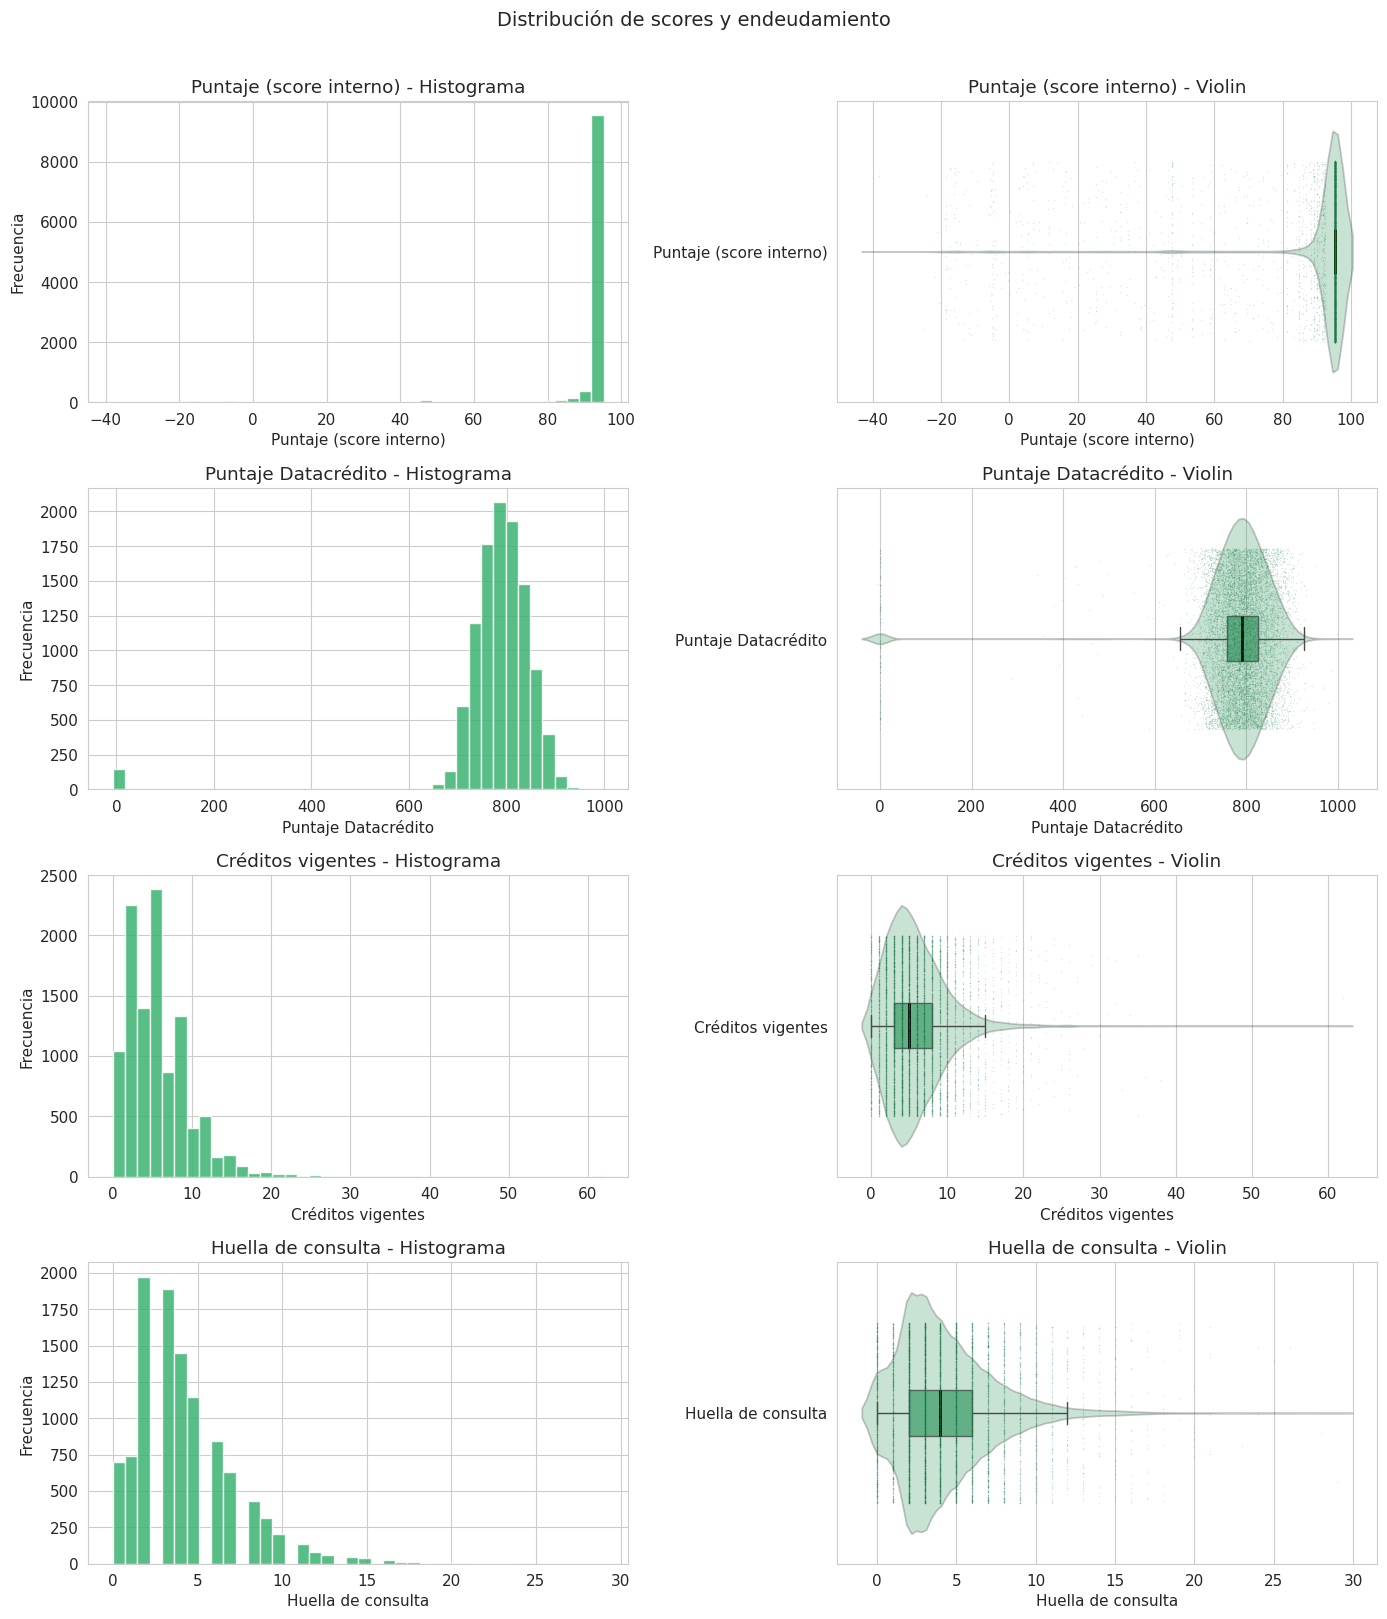

In [ ]:
# 3.1.6. Visualización univariable - Scores y endeudamiento

vars_score = ['puntaje', 'puntaje_datacredito',
              'cant_creditosvigentes', 'huella_consulta']
titulos = ['Puntaje (score interno)', 'Puntaje Datacrédito',
           'Créditos vigentes', 'Huella de consulta']

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
fig.suptitle('Distribución de scores y endeudamiento',
             fontsize=14, y=1.01)

for i, (var, titulo) in enumerate(zip(vars_score, titulos)):
    datos = df[[var]].dropna()
    datos['grupo'] = titulo

    # Histograma (izquierda)
    axes[i, 0].hist(df[var].dropna(), bins=40, color='mediumseagreen',
                    edgecolor='white', alpha=0.85)
    axes[i, 0].set_title(f'{titulo} - Histograma')
    axes[i, 0].set_xlabel(titulo)
    axes[i, 0].set_ylabel('Frecuencia')

    # Violin híbrido (derecha)
    sns.violinplot(data=datos, y='grupo', x=var,
                   color='mediumseagreen', inner=None,
                   alpha=0.3, ax=axes[i, 1])

    sns.boxplot(data=datos, y='grupo', x=var,
                width=0.15, color='mediumseagreen',
                showfliers=False,
                boxprops=dict(alpha=0.8),
                medianprops=dict(color='black', linewidth=2),
                ax=axes[i, 1])

    sns.stripplot(data=datos, y='grupo', x=var,
                  color='#1a7a4a', size=1, alpha=0.15,
                  jitter=0.3, ax=axes[i, 1])

    axes[i, 1].set_title(f'{titulo} - Violin')
    axes[i, 1].set_xlabel(titulo)
    axes[i, 1].set_ylabel('')

plt.tight_layout()
plt.show()

### 3.1.7. Visualización univariable - Saldos reportados
(Vista filtrada al percentil 99 para saldo_total y saldo_principal dado que tienen la misma compresión por outliers)

Variables con distribuciones muy similares (normal de acuerdo con el contexto, saldo principal está contenido en saldo total por lo general)

Sesgo a la derecha. La mayoría se encuentra con saldos en 0.

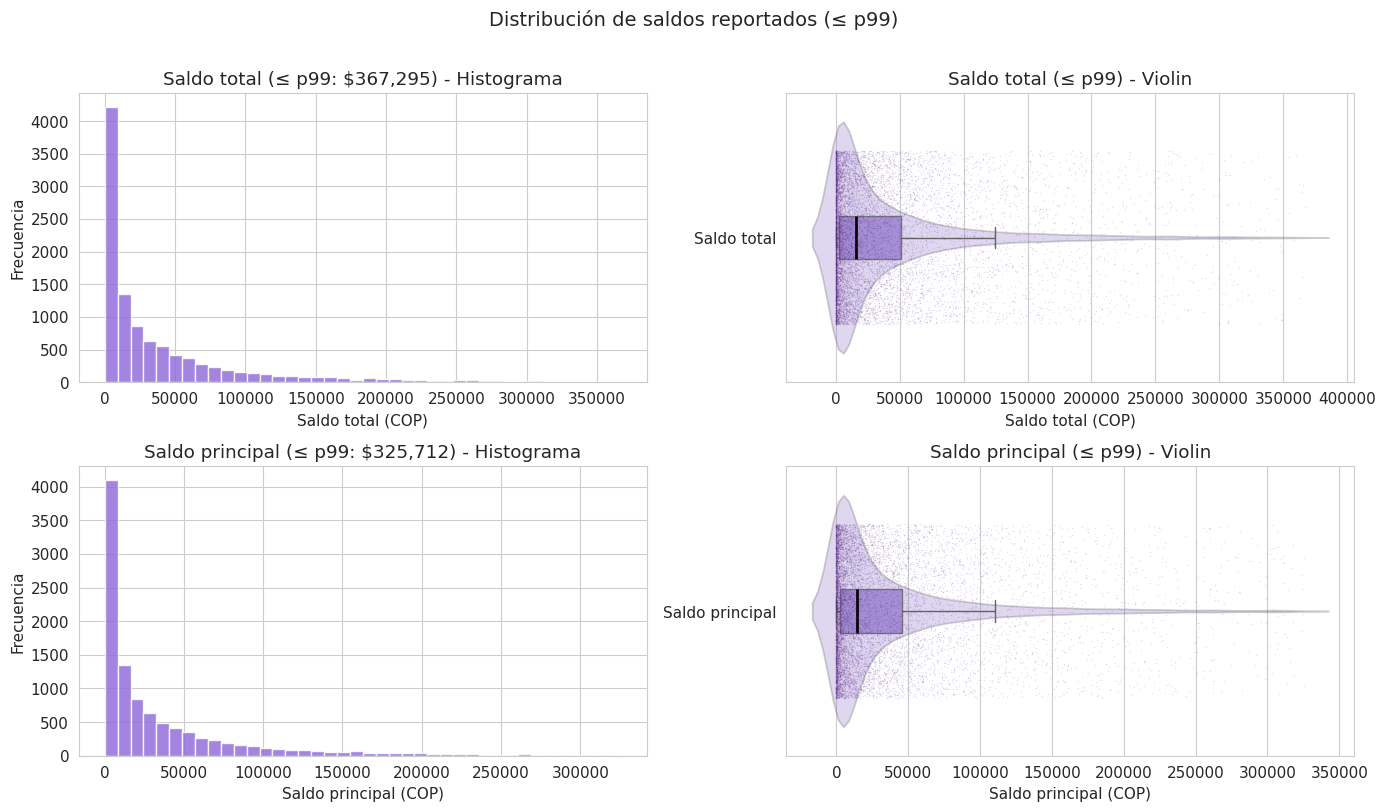

In [ ]:
# 3.1.7. Visualización univariable - Saldos reportados
# (Filtrados al p99 para visualización)

vars_saldos = ['saldo_total', 'saldo_principal']
titulos_saldos = ['Saldo total', 'Saldo principal']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Distribución de saldos reportados (≤ p99)',
             fontsize=14, y=1.01)

for i, (var, titulo) in enumerate(zip(vars_saldos, titulos_saldos)):
    p99 = df[var].quantile(0.99)
    datos = df.loc[df[var] <= p99, [var]].dropna()
    datos['grupo'] = titulo

    # Histograma (izquierda)
    axes[i, 0].hist(datos[var], bins=40, color='mediumpurple',
                    edgecolor='white', alpha=0.85)
    axes[i, 0].set_title(f'{titulo} (≤ p99: ${p99:,.0f}) - Histograma')
    axes[i, 0].set_xlabel(f'{titulo} (COP)')
    axes[i, 0].set_ylabel('Frecuencia')

    # Violin híbrido (derecha)
    sns.violinplot(data=datos, y='grupo', x=var,
                   color='mediumpurple', inner=None,
                   alpha=0.3, ax=axes[i, 1])

    sns.boxplot(data=datos, y='grupo', x=var,
                width=0.15, color='mediumpurple',
                showfliers=False,
                boxprops=dict(alpha=0.8),
                medianprops=dict(color='black', linewidth=2),
                ax=axes[i, 1])

    sns.stripplot(data=datos, y='grupo', x=var,
                  color='#5b2c8a', size=1, alpha=0.15,
                  jitter=0.3, ax=axes[i, 1])

    axes[i, 1].set_title(f'{titulo} (≤ p99) - Violin')
    axes[i, 1].set_xlabel(f'{titulo} (COP)')
    axes[i, 1].set_ylabel('')

plt.tight_layout()
plt.show()

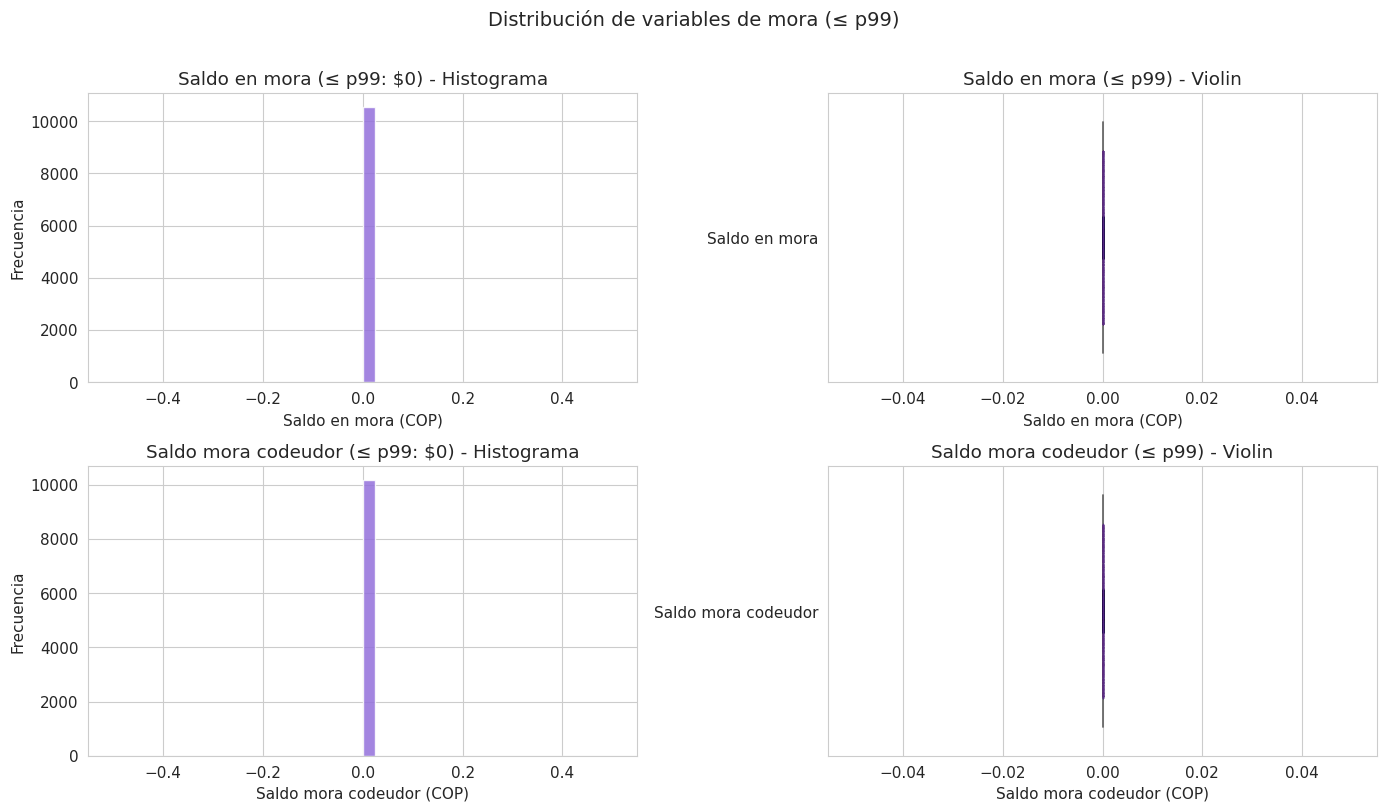

Saldo en mora: 10552 registros en $0 (99.5%) | Con mora > 0: 55
Saldo mora codeudor: 10170 registros en $0 (100.0%) | Con mora > 0: 3


In [ ]:
# 3.1.7b. Visualización univariable - Variables de mora

vars_mora = ['saldo_mora', 'saldo_mora_codeudor']
titulos_mora = ['Saldo en mora', 'Saldo mora codeudor']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Distribución de variables de mora (≤ p99)',
             fontsize=14, y=1.01)

for i, (var, titulo) in enumerate(zip(vars_mora, titulos_mora)):
    p99 = df[var].quantile(0.99)
    datos = df.loc[df[var] <= p99, [var]].dropna()
    datos['grupo'] = titulo

    # Histograma (izquierda)
    axes[i, 0].hist(datos[var], bins=40, color='mediumpurple',
                    edgecolor='white', alpha=0.85)
    axes[i, 0].set_title(f'{titulo} (≤ p99: ${p99:,.0f}) - Histograma')
    axes[i, 0].set_xlabel(f'{titulo} (COP)')
    axes[i, 0].set_ylabel('Frecuencia')

    # Violin híbrido (derecha)
    sns.violinplot(data=datos, y='grupo', x=var,
                   color='mediumpurple', inner=None,
                   alpha=0.3, ax=axes[i, 1])

    sns.boxplot(data=datos, y='grupo', x=var,
                width=0.15, color='mediumpurple',
                showfliers=False,
                boxprops=dict(alpha=0.8),
                medianprops=dict(color='black', linewidth=2),
                ax=axes[i, 1])

    sns.stripplot(data=datos, y='grupo', x=var,
                  color='#5b2c8a', size=1, alpha=0.15,
                  jitter=0.3, ax=axes[i, 1])

    axes[i, 1].set_title(f'{titulo} (≤ p99) - Violin')
    axes[i, 1].set_xlabel(f'{titulo} (COP)')
    axes[i, 1].set_ylabel('')

plt.tight_layout()
plt.show()

# Contexto numérico
for var, titulo in zip(vars_mora, titulos_mora):
    datos = df[var].dropna()
    ceros = (datos == 0).sum()
    print(f"{titulo}: {ceros} registros en $0 ({ceros/len(datos):.1%}) "
          f"| Con mora > 0: {(datos > 0).sum()}")

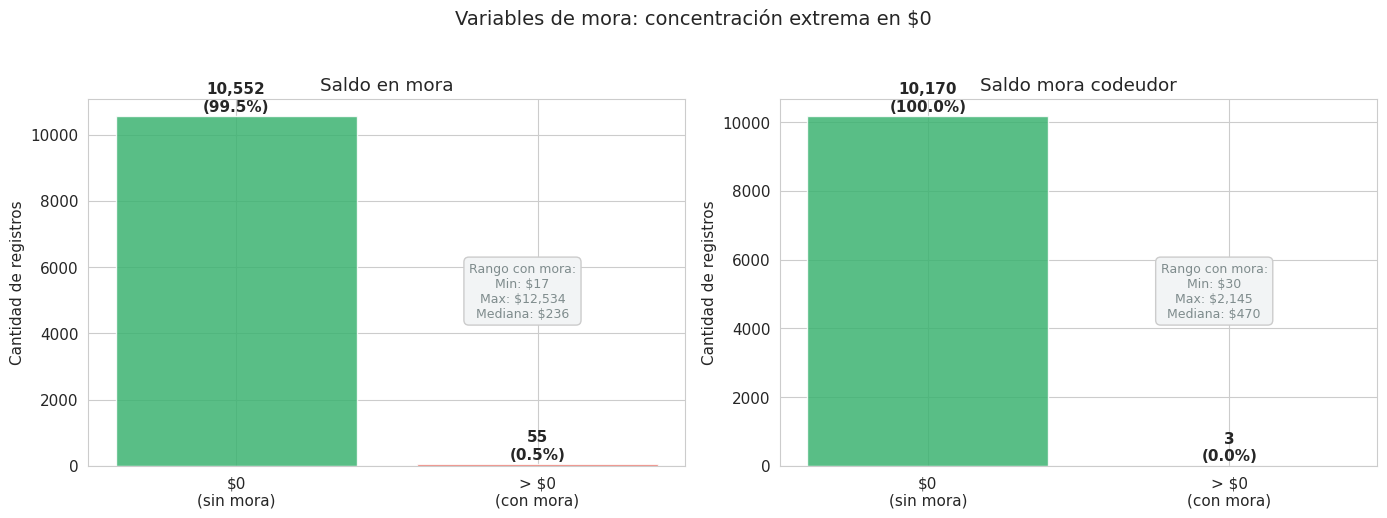

In [ ]:
# 3.1.7b. Variables de mora - Enfoque apropiado para variables
#          con concentración extrema en cero

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Variables de mora: concentración extrema en $0',
             fontsize=14, y=1.03)

vars_mora = ['saldo_mora', 'saldo_mora_codeudor']
titulos_mora = ['Saldo en mora', 'Saldo mora codeudor']

for i, (var, titulo) in enumerate(zip(vars_mora, titulos_mora)):
    datos = df[var].dropna()
    ceros = (datos == 0).sum()
    no_ceros = (datos > 0).sum()
    pct_ceros = ceros / len(datos) * 100

    # Gráfico de barras: ceros vs no ceros
    barras = axes[i].bar(
        ['$0\n(sin mora)', '> $0\n(con mora)'],
        [ceros, no_ceros],
        color=['mediumseagreen', '#e74c3c'],
        edgecolor='white', alpha=0.85
    )
    axes[i].set_title(titulo)
    axes[i].set_ylabel('Cantidad de registros')

    # Etiquetas sobre las barras
    axes[i].text(0, ceros + 150,
                 f'{ceros:,}\n({pct_ceros:.1f}%)',
                 ha='center', fontsize=11, fontweight='bold')
    axes[i].text(1, no_ceros + 150,
                 f'{no_ceros}\n({100-pct_ceros:.1f}%)',
                 ha='center', fontsize=11, fontweight='bold')

    # Si hay registros con mora, mostrar su rango
    if no_ceros > 0:
        mora_vals = datos[datos > 0]
        axes[i].text(0.95, ceros * 0.5,
                     f'Rango con mora:\n'
                     f'Min: ${mora_vals.min():,.0f}\n'
                     f'Max: ${mora_vals.max():,.0f}\n'
                     f'Mediana: ${mora_vals.median():,.0f}',
                     fontsize=9, color='#7f8c8d',
                     ha='center', va='center',
                     bbox=dict(boxstyle='round,pad=0.4',
                               facecolor='#f2f4f5',
                               edgecolor='#cccccc'))

plt.tight_layout()
plt.show()

### 3.1.8. Visualización univariable - Variables categóricas
Desbalance severo de la variable objetivo. Se requeriría el uso de técnicas de balanceo para la creación de modelos predictivos.

Mayoría de tipo laboral son empleados.

Tipo de crédito 4 es el más común, puede especularse que se trata de crédito de cosumo al relacionarlo con que la mayoría de capital prestado es por montos bajos con plazos cortos y con una cuota pequeña respecto a salarios de alrededor de 3 millones de pesos.

La tendencia de ingresos más común es creciente.

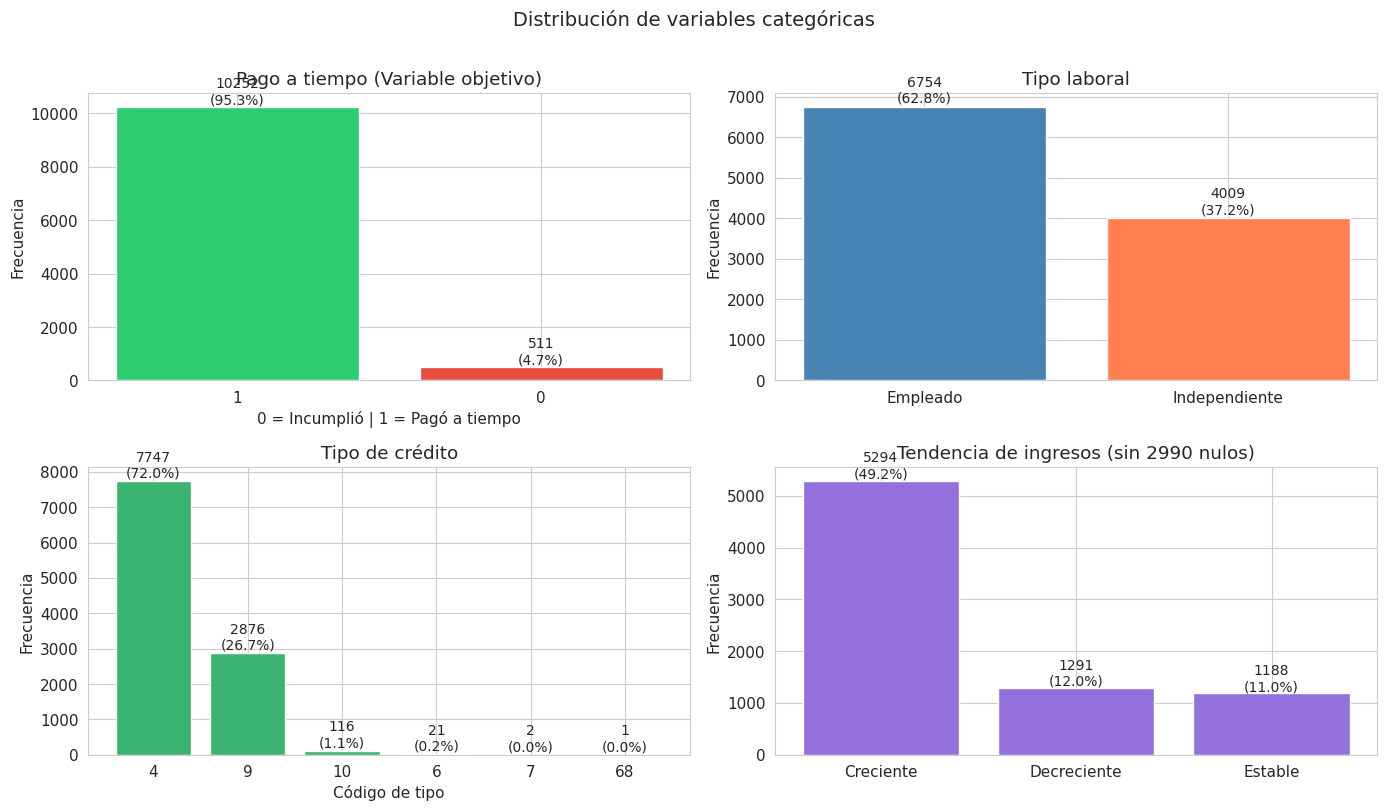

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Distribución de variables categóricas',
             fontsize=14, y=1.01)

# Pago_atiempo (variable objetivo)
conteo_pago = df['Pago_atiempo'].value_counts()
axes[0, 0].bar(conteo_pago.index.astype(str), conteo_pago.values,
               color=['#2ecc71', '#e74c3c'], edgecolor='white')
axes[0, 0].set_title('Pago a tiempo (Variable objetivo)')
axes[0, 0].set_xlabel('0 = Incumplió | 1 = Pagó a tiempo')
axes[0, 0].set_ylabel('Frecuencia')
for j, v in enumerate(conteo_pago.values):
    axes[0, 0].text(j, v + 100, f'{v}\n({v/len(df):.1%})',
                    ha='center', fontsize=10)

# Tipo laboral
conteo_lab = df['tipo_laboral'].value_counts()
axes[0, 1].bar(conteo_lab.index, conteo_lab.values,
               color=['steelblue', 'coral'], edgecolor='white')
axes[0, 1].set_title('Tipo laboral')
axes[0, 1].set_ylabel('Frecuencia')
for j, v in enumerate(conteo_lab.values):
    axes[0, 1].text(j, v + 100, f'{v}\n({v/len(df):.1%})',
                    ha='center', fontsize=10)

# Tipo crédito
conteo_cred = df['tipo_credito'].value_counts()
axes[1, 0].bar(conteo_cred.index.astype(str), conteo_cred.values,
               color='mediumseagreen', edgecolor='white')
axes[1, 0].set_title('Tipo de crédito')
axes[1, 0].set_xlabel('Código de tipo')
axes[1, 0].set_ylabel('Frecuencia')
for j, v in enumerate(conteo_cred.values):
    axes[1, 0].text(j, v + 100, f'{v}\n({v/len(df):.1%})',
                    ha='center', fontsize=10)

# Tendencia ingresos (sin nulos)
conteo_tend = df['tendencia_ingresos'].value_counts()
axes[1, 1].bar(conteo_tend.index, conteo_tend.values,
               color='mediumpurple', edgecolor='white')
axes[1, 1].set_title(f'Tendencia de ingresos (sin {df["tendencia_ingresos"].isna().sum()} nulos)')
axes[1, 1].set_ylabel('Frecuencia')
for j, v in enumerate(conteo_tend.values):
    axes[1, 1].text(j, v + 50, f'{v}\n({v/len(df):.1%})',
                    ha='center', fontsize=10)

plt.tight_layout()
plt.show()

### 3.1.9. Visualización univariable - Créditos por sector

El sector financiero es el que tiene una mayor cantidad de créditos (12). El sector cooperativo tiene su mayoría en 0 al igual que el sector real.

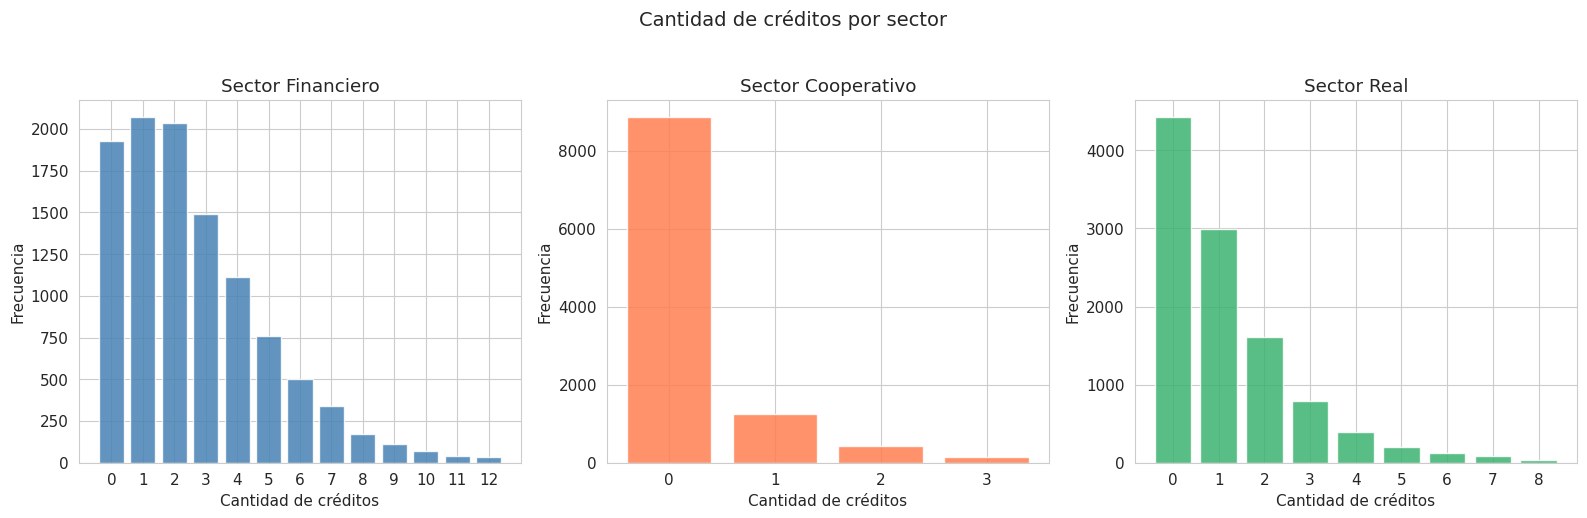

In [ ]:
vars_sector = ['creditos_sectorFinanciero',
               'creditos_sectorCooperativo',
               'creditos_sectorReal']
titulos_sector = ['Sector Financiero', 'Sector Cooperativo',
                  'Sector Real']
colores = ['steelblue', 'coral', 'mediumseagreen']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Cantidad de créditos por sector',
             fontsize=14, y=1.03)

for i, (var, titulo, color) in enumerate(
    zip(vars_sector, titulos_sector, colores)
):
    conteo = df[var].value_counts().sort_index()
    # Mostrar solo hasta el valor donde se acumula el 99%
    acum = conteo.cumsum() / conteo.sum()
    corte = acum[acum <= 0.99].index.max() + 1
    conteo_filt = conteo[conteo.index <= corte]

    axes[i].bar(conteo_filt.index.astype(str), conteo_filt.values,
                color=color, edgecolor='white', alpha=0.85)
    axes[i].set_title(titulo)
    axes[i].set_xlabel('Cantidad de créditos')
    axes[i].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

### 3.1.10. Identificación del tipo de distribución - Variables numéricas

In [ ]:
from scipy import stats

vars_numericas = df.select_dtypes(include='number').columns.tolist()

resultados = []
for var in vars_numericas:
    datos = df[var].dropna()
    sk = datos.skew()
    ku = datos.kurtosis()

    # Clasificación basada en skewness y kurtosis
    if abs(sk) < 0.5 and abs(ku) < 1:
        tipo_dist = 'Aproximadamente simétrica'
    elif abs(sk) < 0.5 and ku > 3:
        tipo_dist = 'Simétrica con colas pesadas (leptocúrtica)'
    elif sk > 2:
        tipo_dist = 'Fuertemente asimétrica derecha (log-normal probable)'
    elif sk > 0.5:
        tipo_dist = 'Asimétrica derecha'
    elif sk < -2:
        tipo_dist = 'Fuertemente asimétrica izquierda'
    elif sk < -0.5:
        tipo_dist = 'Asimétrica izquierda'
    else:
        tipo_dist = 'Otra'

    resultados.append({
        'Variable': var,
        'Skewness': round(sk, 2),
        'Kurtosis': round(ku, 2),
        'Tipo de distribución': tipo_dist
    })

dist_df = pd.DataFrame(resultados)
dist_df

,Variable,Skewness,Kurtosis,Tipo de distribución
0,capital_prestado,3.72,35.32,Fuertemente asimétrica derecha (log-normal pro...
1,plazo_meses,2.46,7.78,Fuertemente asimétrica derecha (log-normal pro...
2,edad_cliente,1.93,7.87,Asimétrica derecha
3,salario_cliente,43.78,"2,211.23",Fuertemente asimétrica derecha (log-normal pro...
4,total_otros_prestamos,38.46,"1,719.28",Fuertemente asimétrica derecha (log-normal pro...
5,cuota_pactada,3.79,26.65,Fuertemente asimétrica derecha (log-normal pro...
6,puntaje,-4.87,24.08,Fuertemente asimétrica izquierda
7,puntaje_datacredito,-5.64,39.44,Fuertemente asimétrica izquierda
8,cant_creditosvigentes,1.80,8.62,Asimétrica derecha
9,huella_consulta,1.49,4.00,Asimétrica derecha


### 3.1.11. Análisis temporal - fecha_prestamo (univariable + bivariable)

Se ve una tendencia decreciente en el volumen de créditos desembolsados con el tiempo. Hay una tasa de incumplimiento que baja hasta octubre del 2925 y luego crece pero con muestras de valores muy bajos y no es comparable con las tasa de incumplimiento créditos más antiguos.

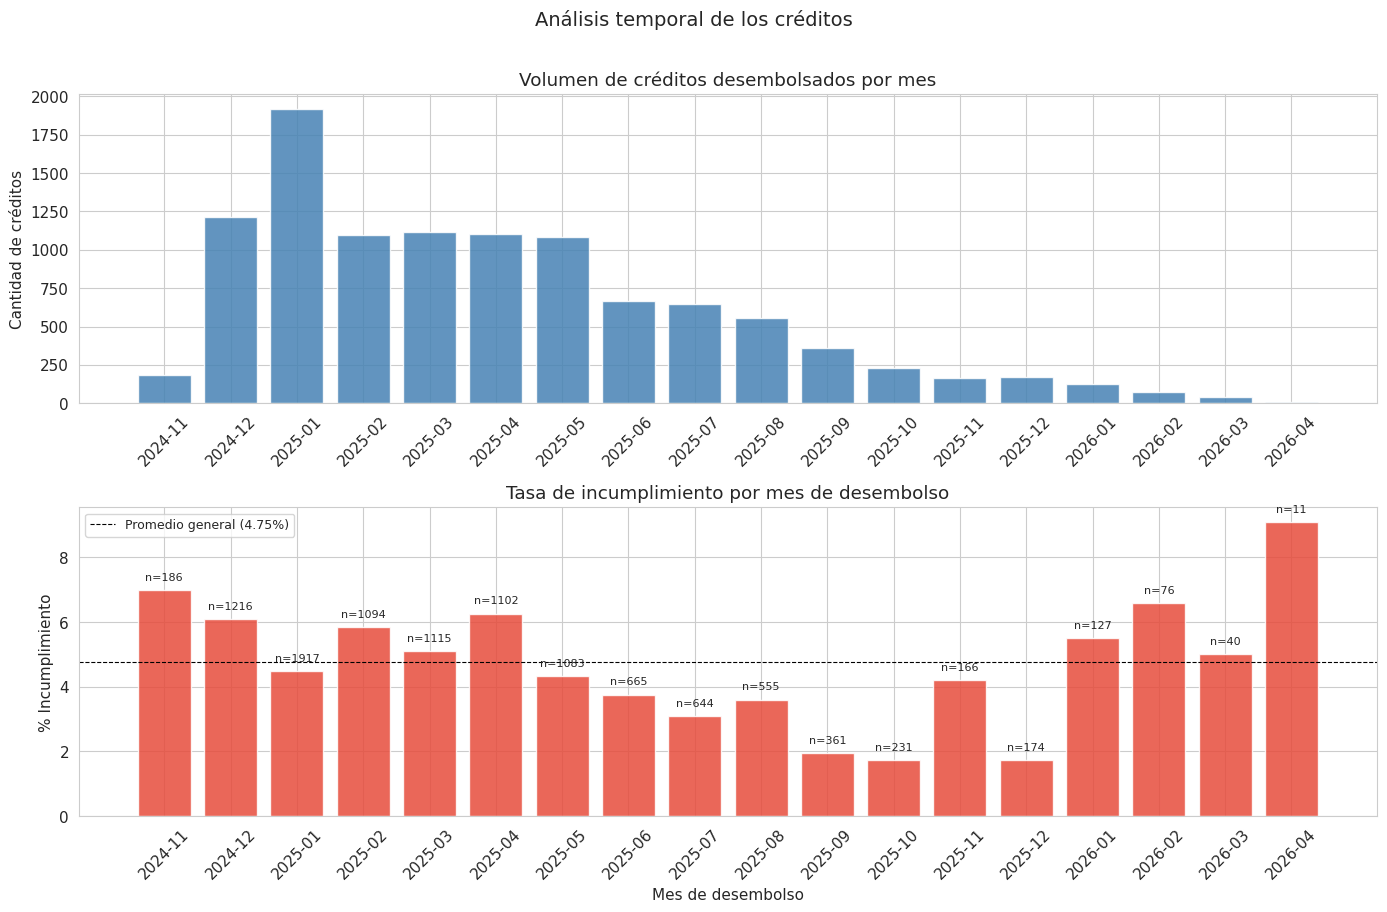

Rango: 26/11/2024 a 26/04/2026
Duración: 516 días


In [ ]:
# Crear variable auxiliar de mes-año para agrupar
df['mes_prestamo'] = df['fecha_prestamo'].dt.to_period('M')

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
fig.suptitle('Análisis temporal de los créditos', fontsize=14, y=1.01)

# --- Univariable: volumen de créditos por mes ---
vol_mensual = df.groupby('mes_prestamo').size()

axes[0].bar(vol_mensual.index.astype(str), vol_mensual.values,
            color='steelblue', edgecolor='white', alpha=0.85)
axes[0].set_title('Volumen de créditos desembolsados por mes')
axes[0].set_ylabel('Cantidad de créditos')
axes[0].tick_params(axis='x', rotation=45)

# --- Bivariable: tasa de incumplimiento por mes ---
tasa_mensual = df.groupby('mes_prestamo')['Pago_atiempo'].apply(
    lambda x: (x == 0).mean() * 100
)
n_mensual = df.groupby('mes_prestamo').size()

bars = axes[1].bar(tasa_mensual.index.astype(str), tasa_mensual.values,
                   color='#e74c3c', edgecolor='white', alpha=0.85)
axes[1].axhline(y=4.75, color='black', linestyle='--',
                linewidth=0.8, label='Promedio general (4.75%)')
axes[1].set_title('Tasa de incumplimiento por mes de desembolso')
axes[1].set_ylabel('% Incumplimiento')
axes[1].set_xlabel('Mes de desembolso')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(fontsize=9)

# Agregar n sobre cada barra
for j, (v, n) in enumerate(zip(tasa_mensual.values, n_mensual.values)):
    axes[1].text(j, v + 0.3, f'n={n}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

# Rango temporal
print(f"Rango: {df['fecha_prestamo'].min().strftime('%d/%m/%Y')} "
      f"a {df['fecha_prestamo'].max().strftime('%d/%m/%Y')}")
print(f"Duración: {(df['fecha_prestamo'].max() - df['fecha_prestamo'].min()).days} días")

In [ ]:
# Verificar si existen créditos recientes con plazos largos
# (que no podrían haber terminado aún)

df['fecha_fin_estimada'] = (
    df['fecha_prestamo'] + pd.to_timedelta(df['plazo_meses'] * 30, unit='D')
)

# Fecha más reciente del dataset como proxy de fecha de extracción
fecha_extraccion = df['fecha_prestamo'].max()
print(f"Fecha del crédito más reciente: {fecha_extraccion.strftime('%d/%m/%Y')}")

# ¿Cuántos créditos tienen fecha de fin estimada posterior a la extracción?
no_terminados = df[df['fecha_fin_estimada'] > fecha_extraccion]
print(f"\nCréditos cuyo plazo NO habría terminado al cierre del dataset:")
print(f"  Total: {len(no_terminados)} de {len(df)} ({len(no_terminados)/len(df):.1%})")
print(f"  Con Pago_atiempo = 1: {(no_terminados['Pago_atiempo'] == 1).sum()}")
print(f"  Con Pago_atiempo = 0: {(no_terminados['Pago_atiempo'] == 0).sum()}")

# Ejemplos de créditos recientes con plazos largos
print(f"\nEjemplos de créditos recientes con plazos largos:")
recientes_largos = df[
    (df['fecha_prestamo'] > '2025-10-01') & (df['plazo_meses'] >= 12)
][['fecha_prestamo', 'plazo_meses', 'fecha_fin_estimada', 'Pago_atiempo']]
print(recientes_largos.head(10))

# Limpiar columna auxiliar
df.drop(columns=['fecha_fin_estimada'], inplace=True)

Fecha del crédito más reciente: 26/04/2026

Créditos cuyo plazo NO habría terminado al cierre del dataset:
  Total: 2141 de 10763 (19.9%)
  Con Pago_atiempo = 1: 2004
  Con Pago_atiempo = 0: 137

Ejemplos de créditos recientes con plazos largos:
         fecha_prestamo  plazo_meses  fecha_fin_estimada Pago_atiempo
15  2025-10-13 15:44:00           18 2027-04-06 15:44:00            1
91  2025-11-28 12:45:00           12 2026-11-23 12:45:00            1
110 2025-10-23 11:02:00           18 2027-04-16 11:02:00            1
125 2026-01-08 15:57:00           12 2027-01-03 15:57:00            1
172 2026-01-09 14:21:00           36 2028-12-24 14:21:00            1
248 2025-10-30 12:48:00           18 2027-04-23 12:48:00            1
376 2026-03-25 11:59:00           12 2027-03-20 11:59:00            1
381 2026-01-23 08:59:00           12 2027-01-18 08:59:00            1
410 2025-11-28 10:52:00           36 2028-11-12 10:52:00            1
420 2026-02-22 10:08:00           12 2027-02-17 10:08:

In [ ]:
print("=" * 65)
print("HALLAZGO CRÍTICO: VARIABLE OBJETIVO (Pago_atiempo)")
print("=" * 65)

total = len(df)
no_terminados = df[
    (df['fecha_prestamo'] + pd.to_timedelta(df['plazo_meses'] * 30, unit='D'))
    > df['fecha_prestamo'].max()
]

print(f"""
La variable Pago_atiempo NO registra el resultado final del crédito,
sino el estado de pago hasta la fecha de extracción de los datos.

Evidencia:
- {len(no_terminados)} créditos ({len(no_terminados)/total:.1%}) tienen un
  plazo que se extiende más allá de la fecha del último registro.
- De estos, {(no_terminados['Pago_atiempo'] == 1).sum()} están marcados
  como Pago_atiempo = 1 (pagó a tiempo), a pesar de que el crédito
  aún no ha terminado.

Implicación:
- Algunos créditos marcados como "pagó a tiempo" podrían incumplir
  en el futuro, generando un SESGO DE MADURACIÓN.
- Los créditos más recientes tienen tasas de incumplimiento más bajas
  NO necesariamente porque sean mejores, sino porque han tenido
  menos tiempo para incumplir.
- Este hallazgo es CRÍTICO para cualquier modelo predictivo futuro.
""")

HALLAZGO CRÍTICO: VARIABLE OBJETIVO (Pago_atiempo)

La variable Pago_atiempo NO registra el resultado final del crédito,
sino el estado de pago hasta la fecha de extracción de los datos.

Evidencia:
- 2141 créditos (19.9%) tienen un
  plazo que se extiende más allá de la fecha del último registro.
- De estos, 2004 están marcados
  como Pago_atiempo = 1 (pagó a tiempo), a pesar de que el crédito
  aún no ha terminado.

Implicación:
- Algunos créditos marcados como "pagó a tiempo" podrían incumplir
  en el futuro, generando un SESGO DE MADURACIÓN.
- Los créditos más recientes tienen tasas de incumplimiento más bajas
  NO necesariamente porque sean mejores, sino porque han tenido
  menos tiempo para incumplir.
- Este hallazgo es CRÍTICO para cualquier modelo predictivo futuro.



## 3.2. Análisis bivariable

###3.2.1. Variables numéricas vs Pago_atiempo (boxplots comparativos)
La edad de quienes cumplen por lo general es mayor (más concentración en valores más altos, media en 42 años).

Puntaje en datacrédito con una mediana ligeramente más baja los que incumplieron.

Los que incumplieron tienen una caja más amplia y una mediana ligeramente más alta, sugiriendo que tenían más consultas recientes. Esto podría indicar que estaban buscando crédito con más urgencia.

En el resto de variables no hay diferencias significativas

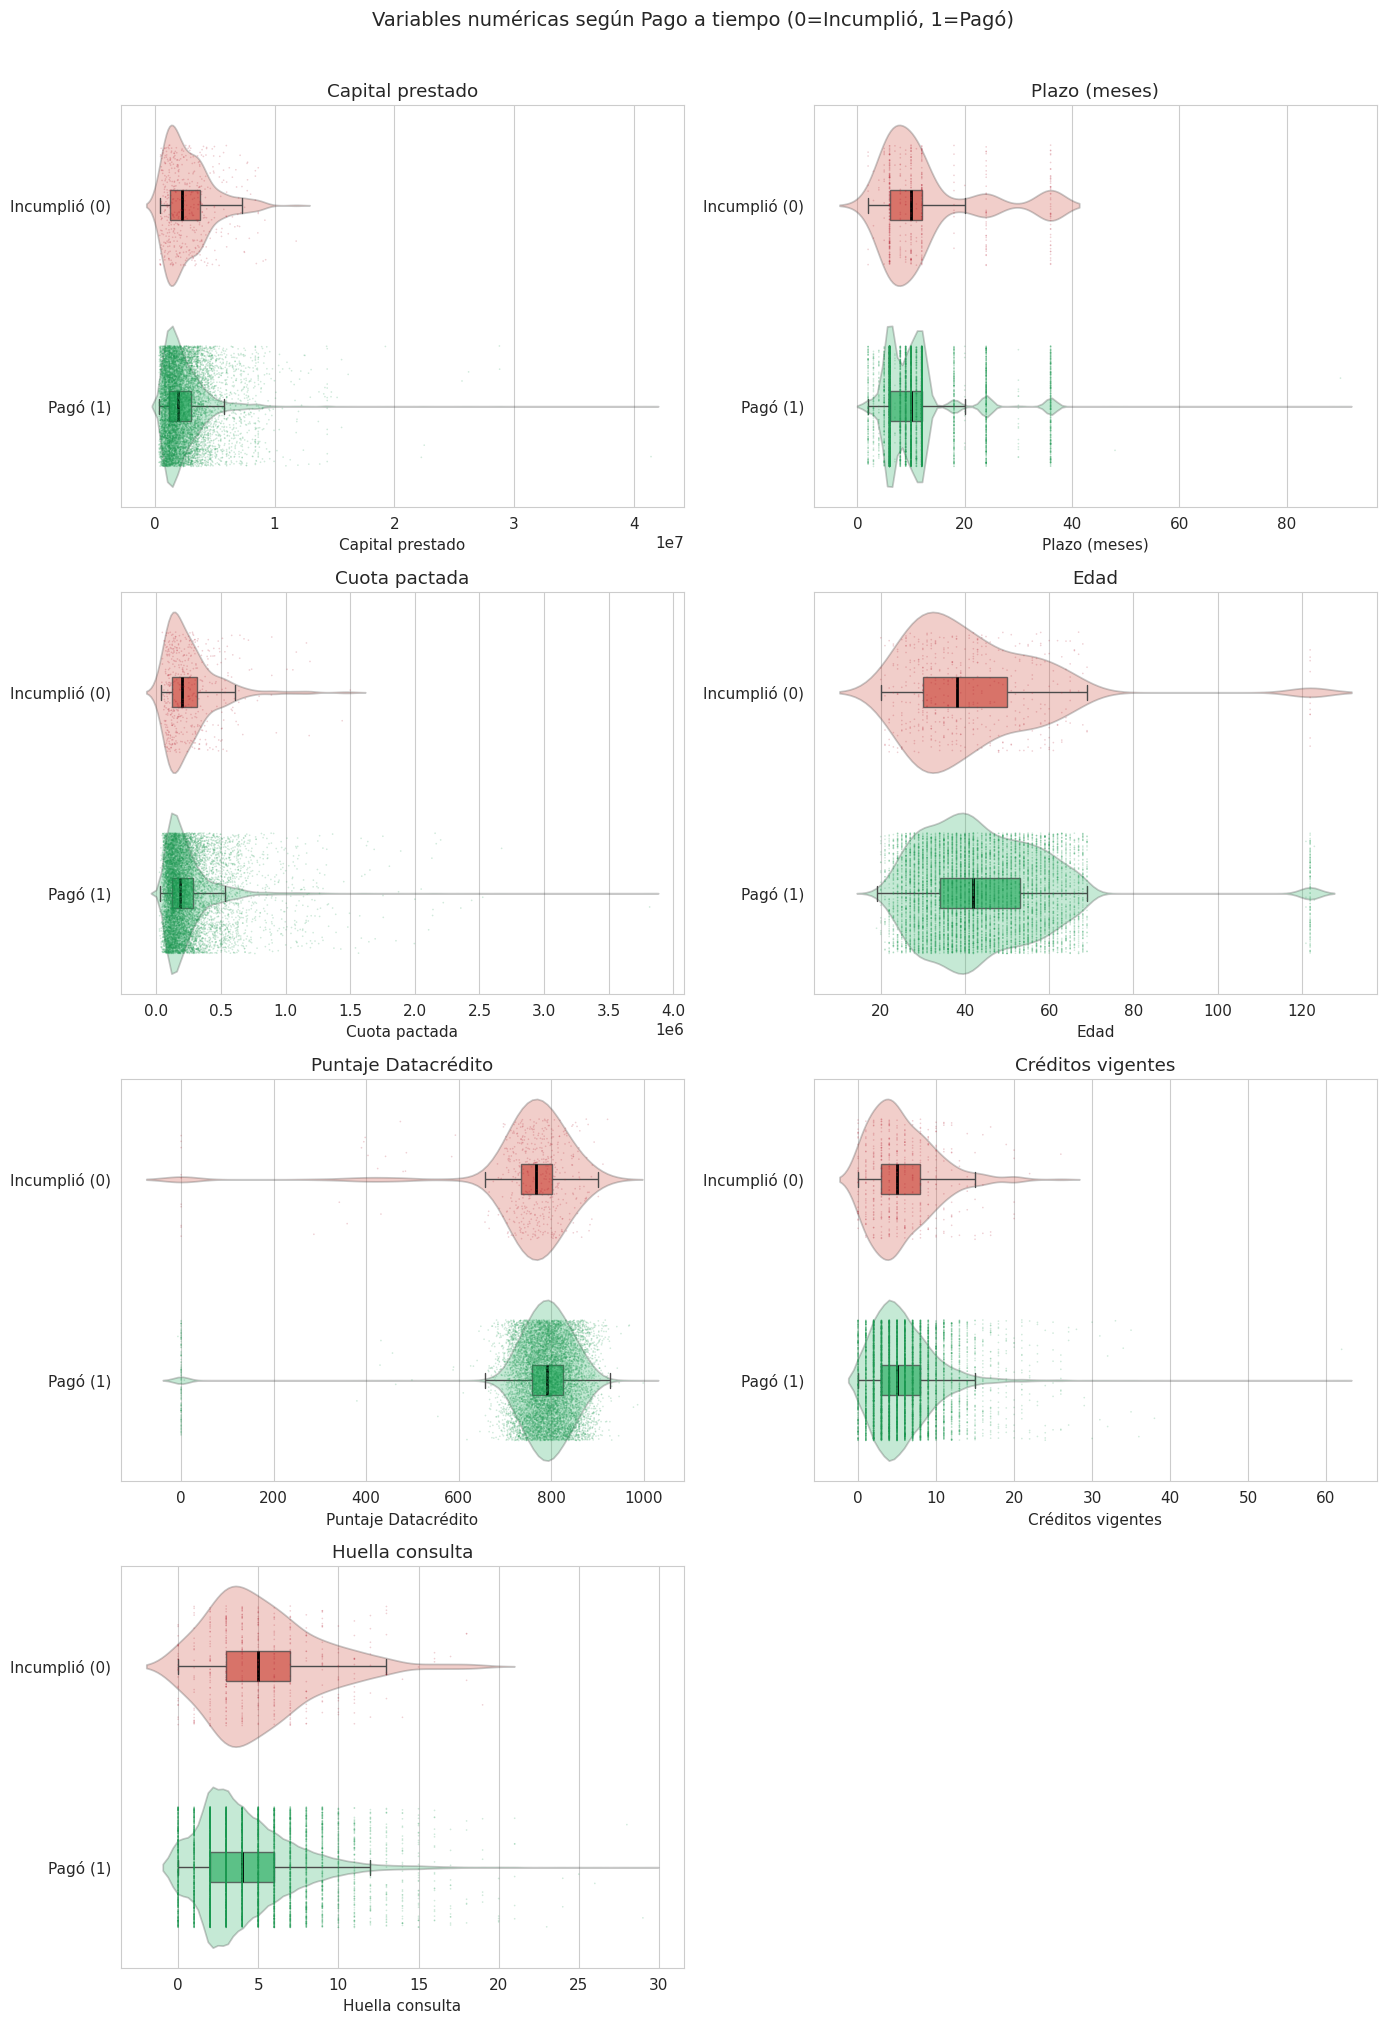

In [ ]:
# 3.2.1. Variables numéricas vs Pago_atiempo (violin híbrido - corregido)

vars_biv = ['capital_prestado', 'plazo_meses', 'cuota_pactada',
            'edad_cliente', 'puntaje_datacredito',
            'cant_creditosvigentes', 'huella_consulta']
titulos_biv = ['Capital prestado', 'Plazo (meses)', 'Cuota pactada',
               'Edad', 'Puntaje Datacrédito',
               'Créditos vigentes', 'Huella consulta']

df['pago_label'] = df['Pago_atiempo'].map(
    {0: 'Incumplió (0)', 1: 'Pagó (1)'}
)

fig, axes = plt.subplots(4, 2, figsize=(14, 20))
fig.suptitle('Variables numéricas según Pago a tiempo (0=Incumplió, 1=Pagó)',
             fontsize=14, y=1.01)

palette = {'Pagó (1)': '#2ecc71', 'Incumplió (0)': '#e74c3c'}

for i, (var, titulo) in enumerate(zip(vars_biv, titulos_biv)):
    fila = i // 2
    col = i % 2
    ax = axes[fila, col]

    datos_plot = df[['pago_label', var]].dropna()

    # Capa 1: Violin
    sns.violinplot(data=datos_plot, y='pago_label', x=var,
                   hue='pago_label', palette=palette, inner=None,
                   alpha=0.3, legend=False, ax=ax)

    # Capa 2: Boxplot
    sns.boxplot(data=datos_plot, y='pago_label', x=var,
                hue='pago_label', width=0.15, palette=palette,
                showfliers=False, legend=False,
                boxprops=dict(alpha=0.8),
                medianprops=dict(color='black', linewidth=2), ax=ax)

    # Capa 3: Strip con colores más fuertes para visibilidad
    palette_puntos = {'Pagó (1)': '#1a9850', 'Incumplió (0)': '#b2182b'}
    sns.stripplot(data=datos_plot, y='pago_label', x=var,
                  hue='pago_label', palette=palette_puntos,
                  size=1.2, alpha=0.2, jitter=0.3,
                  legend=False, ax=ax)

    ax.set_title(titulo)
    ax.set_xlabel(titulo)
    ax.set_ylabel('')

axes[3, 1].set_visible(False)

plt.tight_layout()
plt.show()

df.drop(columns=['pago_label'], inplace=True)

### 3.2.2. Variables financieras del cliente vs Pago_atiempo
(Filtradas al percentil 99 para visualización)

Salarios más bajos de quienes incumplieron. Mismo comportamiento que el promedio de ingresos de datacrédito.

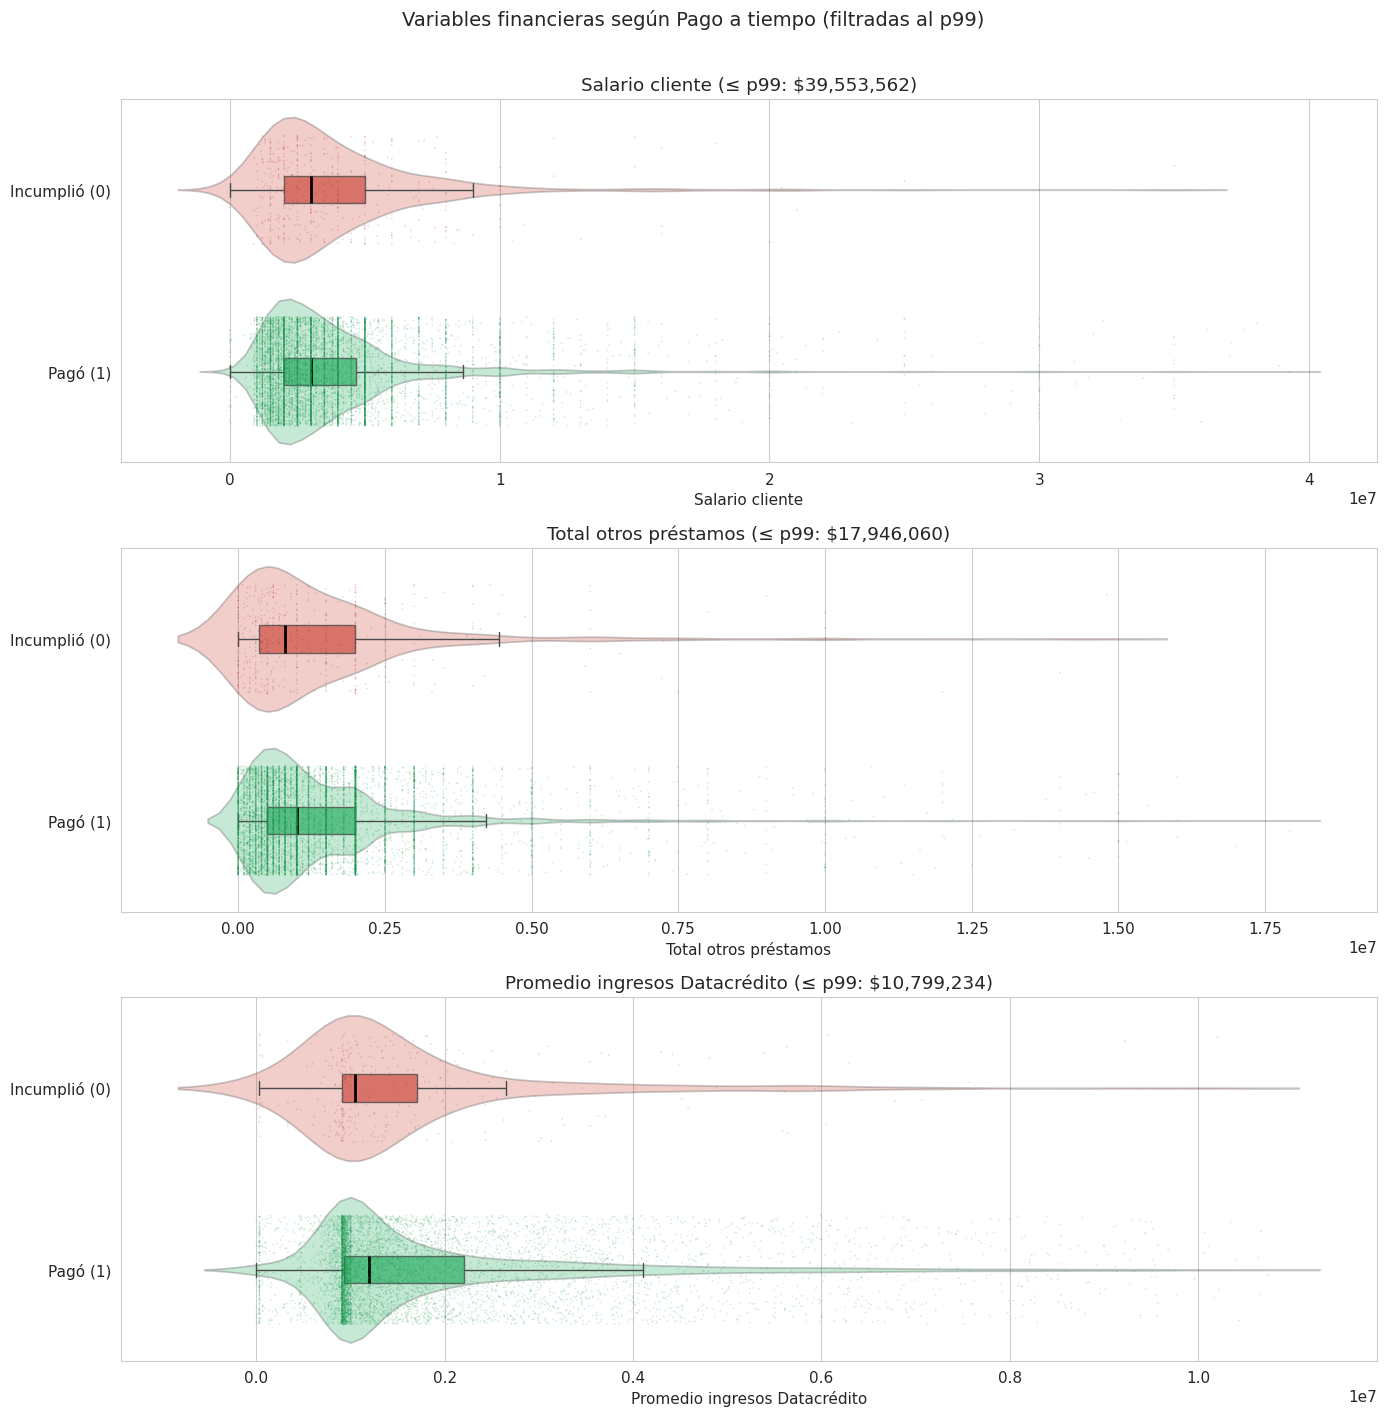

In [ ]:
vars_fin = ['salario_cliente', 'total_otros_prestamos',
            'promedio_ingresos_datacredito']
titulos_fin = ['Salario cliente', 'Total otros préstamos',
               'Promedio ingresos Datacrédito']

df['pago_label'] = df['Pago_atiempo'].map(
    {0: 'Incumplió (0)', 1: 'Pagó (1)'}
)

palette = {'Pagó (1)': '#2ecc71', 'Incumplió (0)': '#e74c3c'}
palette_puntos = {'Pagó (1)': '#1a9850', 'Incumplió (0)': '#b2182b'}

fig, axes = plt.subplots(3, 1, figsize=(14, 14))
fig.suptitle('Variables financieras según Pago a tiempo (filtradas al p99)',
             fontsize=14, y=1.01)

for i, (var, titulo) in enumerate(zip(vars_fin, titulos_fin)):
    p99 = df[var].quantile(0.99)
    datos_plot = df.loc[df[var] <= p99, ['pago_label', var]].dropna()

    sns.violinplot(data=datos_plot, y='pago_label', x=var,
                   hue='pago_label', palette=palette, inner=None,
                   alpha=0.3, legend=False, ax=axes[i])

    sns.boxplot(data=datos_plot, y='pago_label', x=var,
                hue='pago_label', width=0.15, palette=palette,
                showfliers=False, legend=False,
                boxprops=dict(alpha=0.8),
                medianprops=dict(color='black', linewidth=2), ax=axes[i])

    sns.stripplot(data=datos_plot, y='pago_label', x=var,
                  hue='pago_label', palette=palette_puntos,
                  size=1.2, alpha=0.2, jitter=0.3,
                  legend=False, ax=axes[i])

    axes[i].set_title(f'{titulo} (≤ p99: ${p99:,.0f})')
    axes[i].set_xlabel(titulo)
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

df.drop(columns=['pago_label'], inplace=True)

### 3.2.3. Saldos, puntaje y créditos por sector vs Pago_atiempo
Puntaje con diferencia contundente entre quienes cumplieron e incumplieron (cumplieron solo los valores más altos). Se sospecha que la variable es un modelo predictivo.

En saldos total y principal incumplen quienes los tiene reportados con valores más altos.

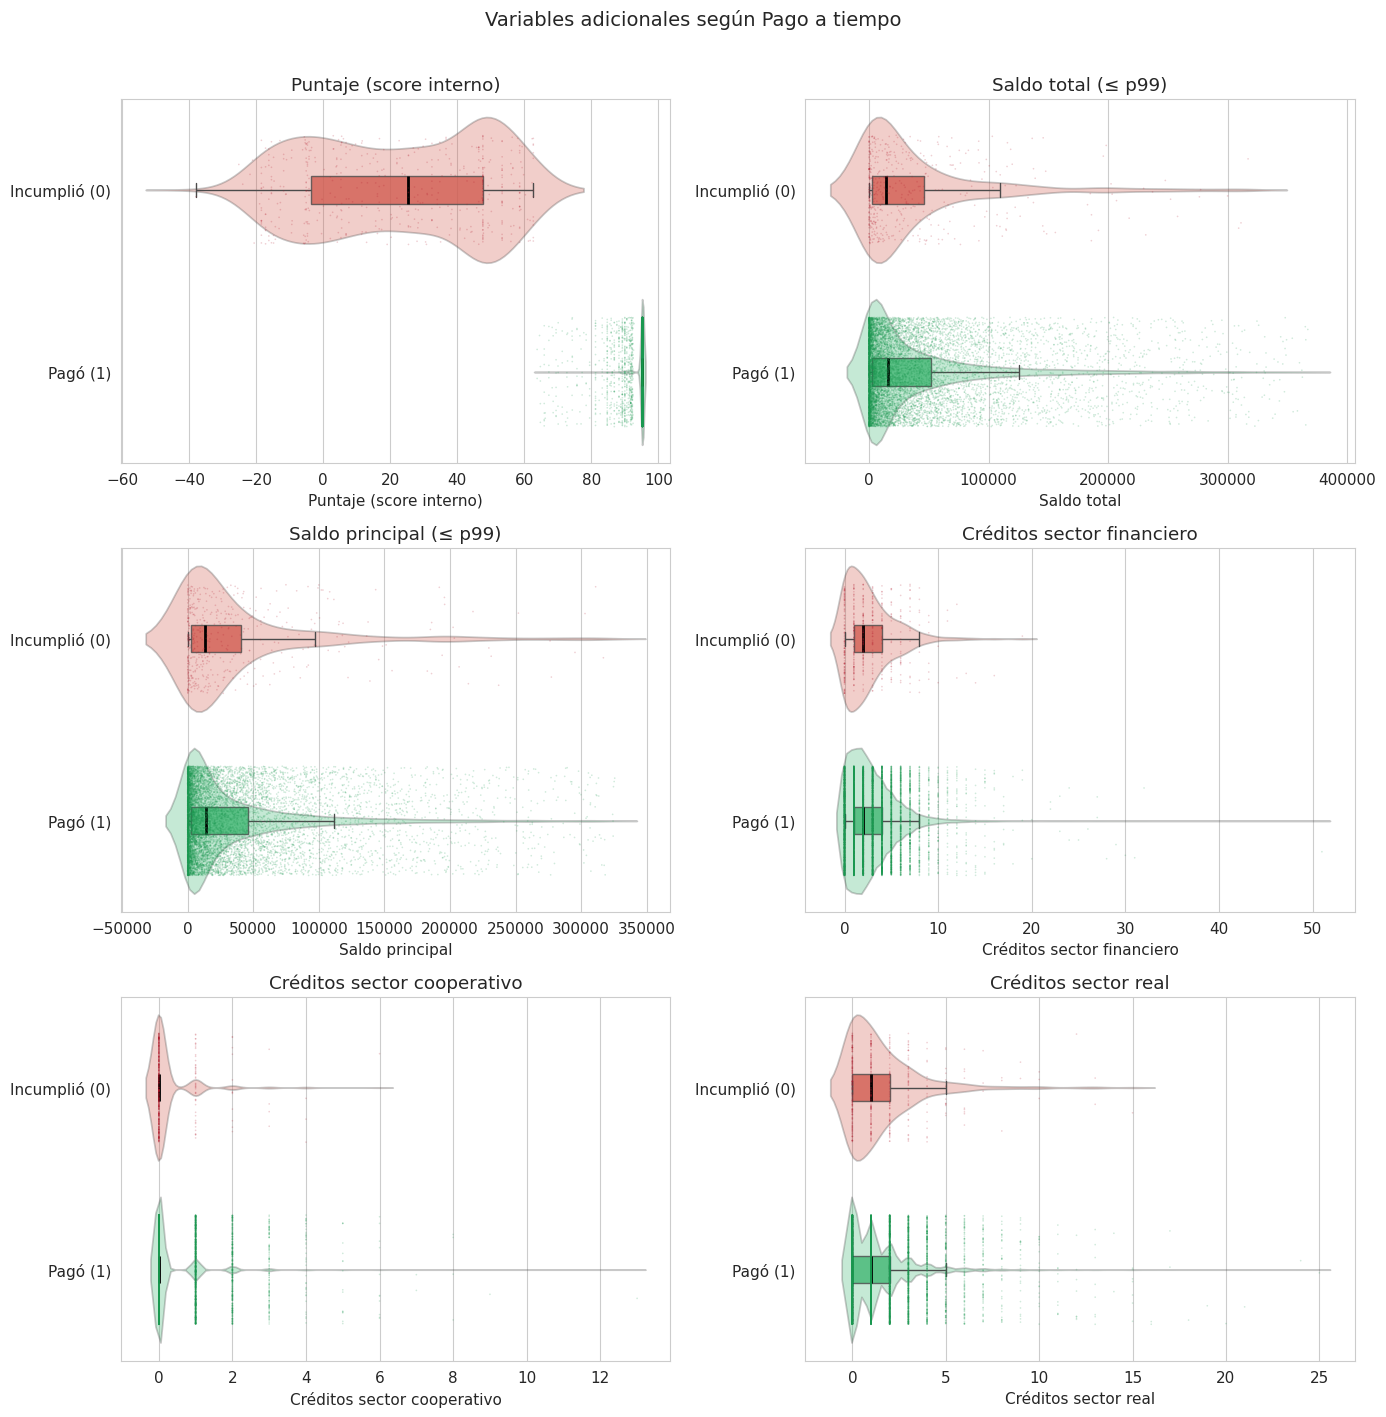

In [ ]:
n
# 3.2.4. Saldos, puntaje y créditos por sector vs Pago_atiempo (violin híbrido)

vars_rest = ['puntaje', 'saldo_total', 'saldo_principal',
             'creditos_sectorFinanciero', 'creditos_sectorCooperativo',
             'creditos_sectorReal']
titulos_rest = ['Puntaje (score interno)', 'Saldo total', 'Saldo principal',
                'Créditos sector financiero', 'Créditos sector cooperativo',
                'Créditos sector real']

df['pago_label'] = df['Pago_atiempo'].map(
    {0: 'Incumplió (0)', 1: 'Pagó (1)'}
)

palette = {'Pagó (1)': '#2ecc71', 'Incumplió (0)': '#e74c3c'}
palette_puntos = {'Pagó (1)': '#1a9850', 'Incumplió (0)': '#b2182b'}

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
fig.suptitle('Variables adicionales según Pago a tiempo',
             fontsize=14, y=1.01)

for i, (var, titulo) in enumerate(zip(vars_rest, titulos_rest)):
    fila = i // 2
    col = i % 2
    ax = axes[fila, col]

    if var in ['saldo_total', 'saldo_principal']:
        p99 = df[var].quantile(0.99)
        datos_plot = df.loc[df[var] <= p99, ['pago_label', var]].dropna()
        ax.set_title(f'{titulo} (≤ p99)')
    else:
        datos_plot = df[['pago_label', var]].dropna()
        ax.set_title(titulo)

    sns.violinplot(data=datos_plot, y='pago_label', x=var,
                   hue='pago_label', palette=palette, inner=None,
                   alpha=0.3, legend=False, ax=ax)

    sns.boxplot(data=datos_plot, y='pago_label', x=var,
                hue='pago_label', width=0.15, palette=palette,
                showfliers=False, legend=False,
                boxprops=dict(alpha=0.8),
                medianprops=dict(color='black', linewidth=2), ax=ax)

    sns.stripplot(data=datos_plot, y='pago_label', x=var,
                  hue='pago_label', palette=palette_puntos,
                  size=1.2, alpha=0.2, jitter=0.3,
                  legend=False, ax=ax)

    ax.set_xlabel(titulo)
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

df.drop(columns=['pago_label'], inplace=True)

### 3.2.4. Variables categóricas vs Pago_atiempo

La tendencia creciente de créditos tiene ligeramente un menor porcentaje de incumplimiento que el resto de tendencias.
El tipo de crédito con más morosos es el 6 pero tiene pocas muestras.
El tipo laboral como empleado tiene menos morosos y tiene más muestras que el tipo independiente.

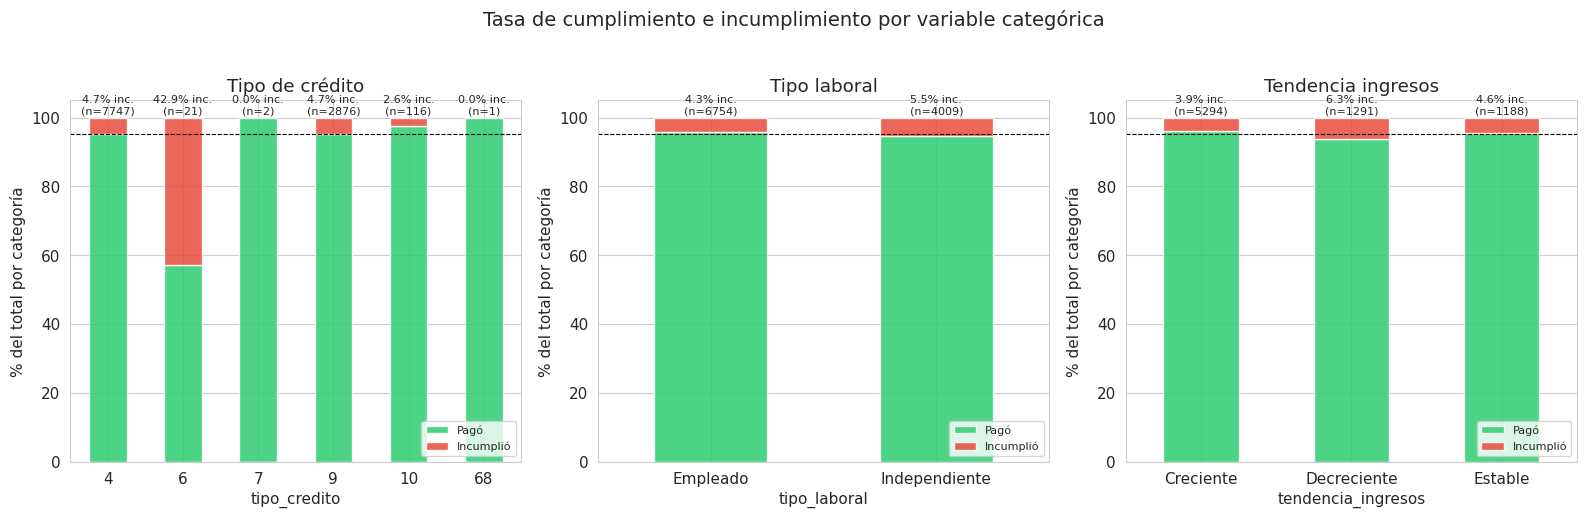

In [ ]:
vars_cat_biv = ['tipo_credito', 'tipo_laboral', 'tendencia_ingresos']
titulos_cat = ['Tipo de crédito', 'Tipo laboral', 'Tendencia ingresos']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Tasa de cumplimiento e incumplimiento por variable categórica',
             fontsize=14, y=1.03)

for i, (var, titulo) in enumerate(zip(vars_cat_biv, titulos_cat)):
    tabla = pd.crosstab(df[var], df['Pago_atiempo'], normalize='index') * 100
    tabla.columns = ['Incumplió', 'Pagó']

    tabla[['Pagó', 'Incumplió']].plot(
        kind='bar', stacked=True, ax=axes[i],
        color=['#2ecc71', '#e74c3c'], edgecolor='white', alpha=0.85
    )

    axes[i].set_title(titulo)
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('% del total por categoría')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=0)
    axes[i].legend(fontsize=8, loc='lower right')
    axes[i].axhline(y=95.25, color='black', linestyle='--',
                    linewidth=0.8)

    # Agregar porcentaje de incumplimiento y n sobre cada barra
    for j, cat in enumerate(tabla.index):
        n = df[df[var] == cat].shape[0]
        pct_inc = tabla.loc[cat, 'Incumplió']
        axes[i].text(j, 101, f'{pct_inc:.1f}% inc.\n(n={n})',
                     ha='center', fontsize=8)

plt.tight_layout()
plt.show()

## 3.3. Análisis multivariable

### 3.3.1. Matriz de correlación - Variables numéricas

Evaluar redundancia de:
saldo principal y saldo total (total contiene al principal por lo general)

Cantidad de creditos vigentes con creditos de sector financiero (la mayoría de créditos son del sector financiero)

Capital prestado y cuota pactada (la cuota se determina a partir del capital)


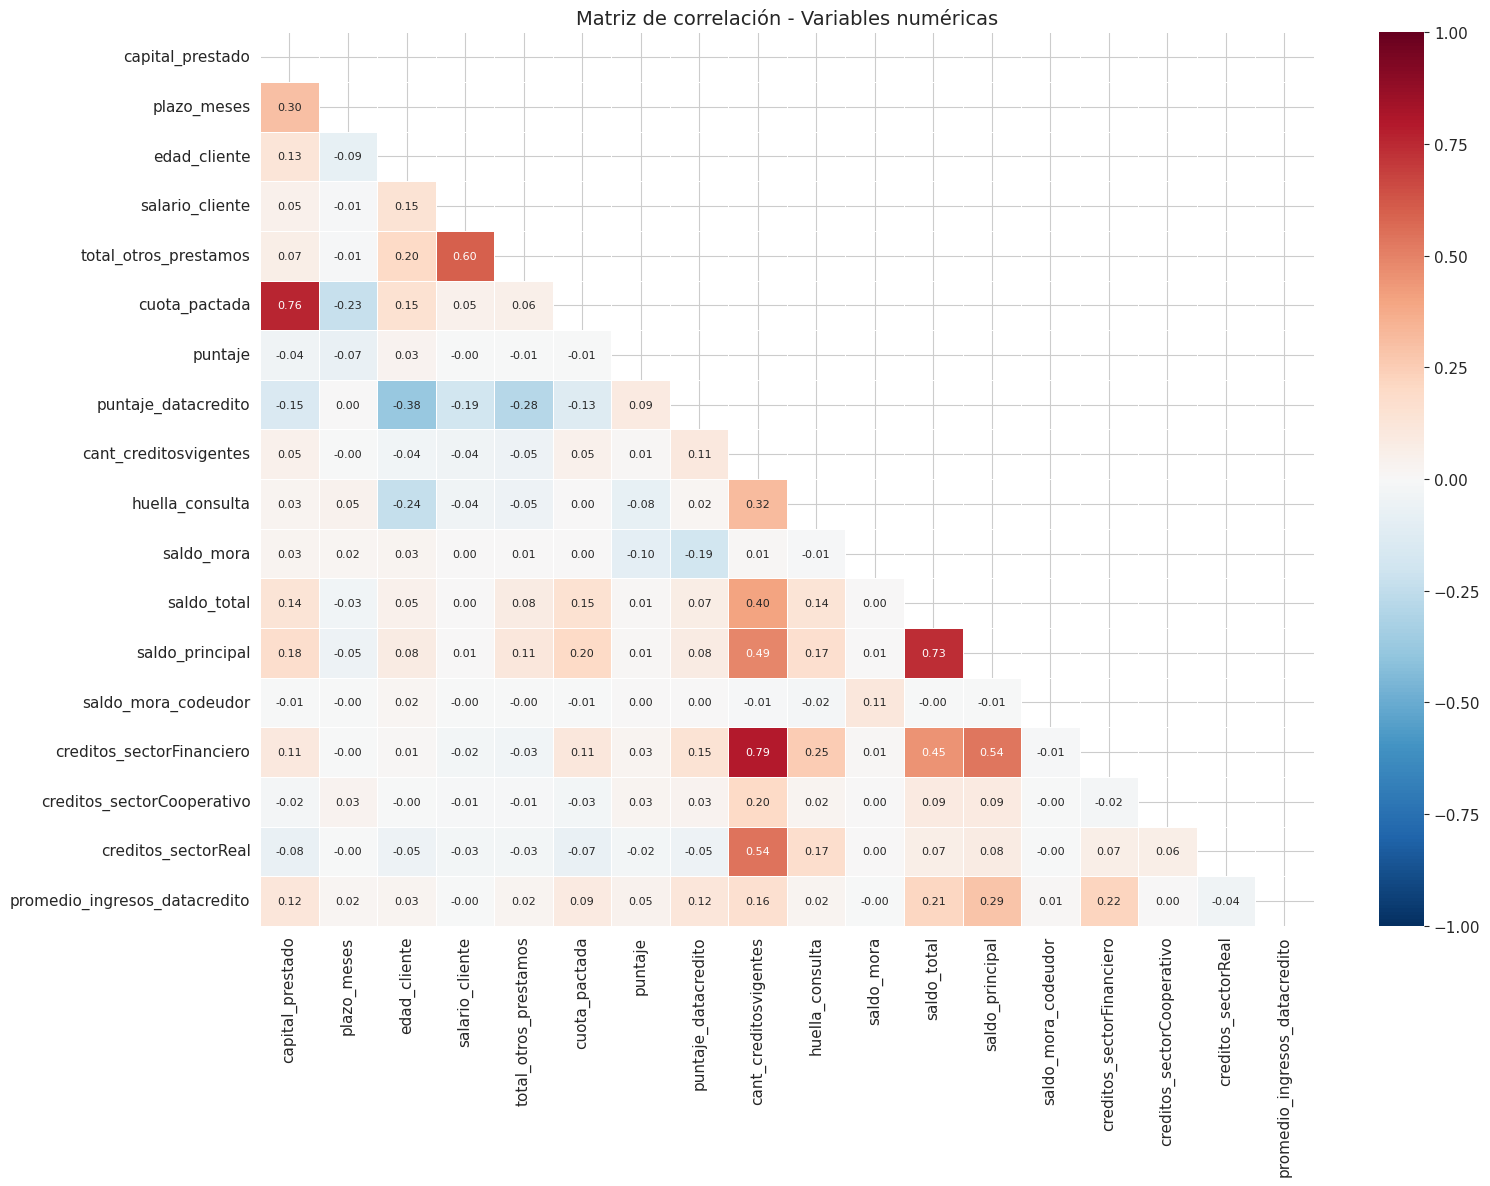

In [ ]:
vars_corr = ['capital_prestado', 'plazo_meses', 'edad_cliente',
             'salario_cliente', 'total_otros_prestamos', 'cuota_pactada',
             'puntaje', 'puntaje_datacredito', 'cant_creditosvigentes',
             'huella_consulta', 'saldo_mora', 'saldo_total',
             'saldo_principal', 'saldo_mora_codeudor',
             'creditos_sectorFinanciero', 'creditos_sectorCooperativo',
             'creditos_sectorReal', 'promedio_ingresos_datacredito']

corr = df[vars_corr].corr()

# Mapa de calor
plt.figure(figsize=(16, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, linewidths=0.5,
            annot_kws={'size': 8})
plt.title('Matriz de correlación - Variables numéricas', fontsize=14)
plt.tight_layout()
plt.show()

### 3.3.2. Correlación de cada variable numérica con la variable objetivo
El puntaje tiene una correlación muy fuerte con la variable objetivo. Nuevamente se sospecha que es un modelo predictivo.



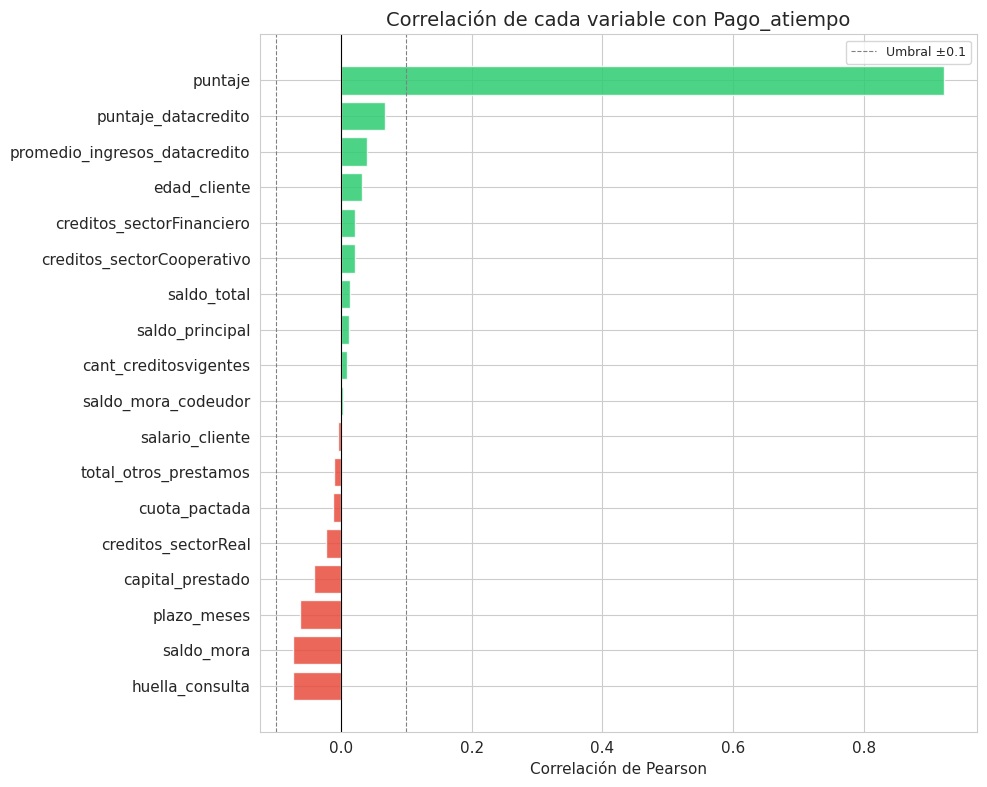

In [ ]:
pago_numerico = df['Pago_atiempo'].astype(int)

corr_target = df[vars_corr].corrwith(pago_numerico).sort_values()

plt.figure(figsize=(10, 8))
colores = ['#e74c3c' if v < 0 else '#2ecc71' for v in corr_target.values]
plt.barh(corr_target.index, corr_target.values, color=colores,
         edgecolor='white', alpha=0.85)
plt.axvline(x=0, color='black', linewidth=0.8)
plt.axvline(x=0.1, color='gray', linestyle='--', linewidth=0.8,
            label='Umbral ±0.1')
plt.axvline(x=-0.1, color='gray', linestyle='--', linewidth=0.8)
plt.title('Correlación de cada variable con Pago_atiempo', fontsize=14)
plt.xlabel('Correlación de Pearson')
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

### 3.3.3. Pairplot - Variables más relevantes vs variable objetivo

La variable de puntaje comparada con el resto de variables siempre muestra una diferenciación entre los que cumplen y no cumplen, siendo los que cumplen los que tienen los valores más altos.

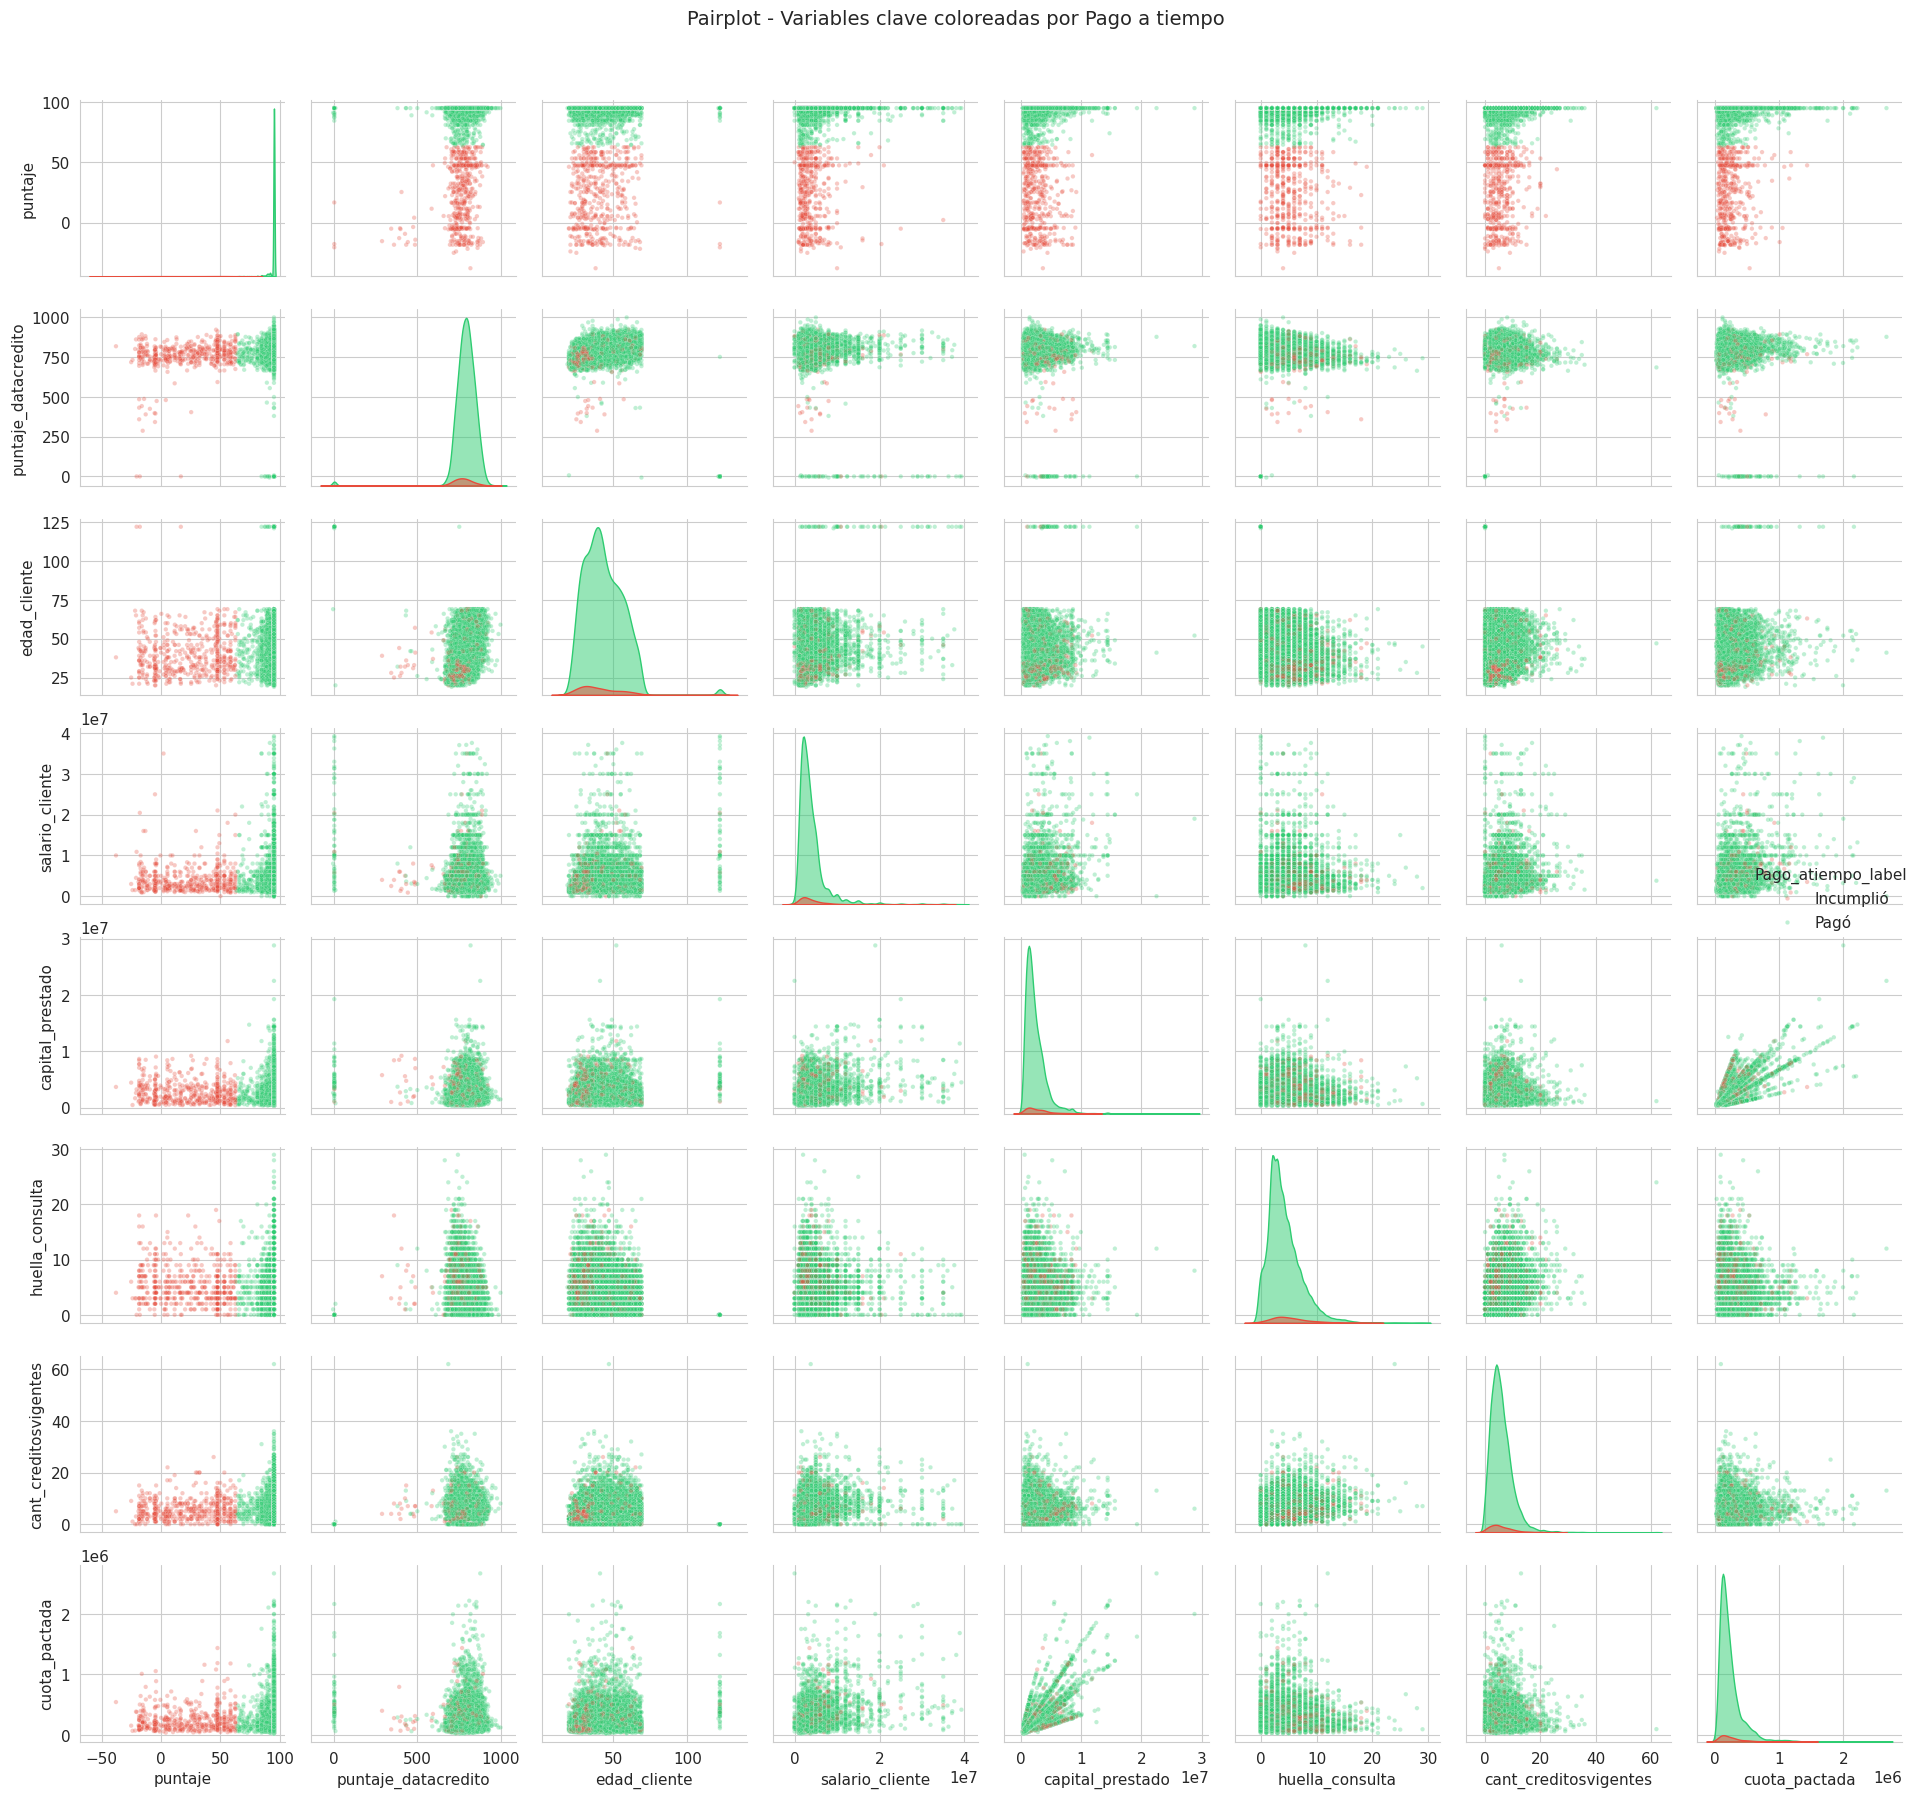

In [ ]:
vars_pairplot = ['puntaje', 'puntaje_datacredito', 'edad_cliente',
                 'salario_cliente', 'capital_prestado', 'huella_consulta', 'cant_creditosvigentes', 'cuota_pactada']

# Filtrar salario al p99 para que el pairplot sea legible
p99_sal = df['salario_cliente'].quantile(0.99)
df_pair = df.loc[df['salario_cliente'] <= p99_sal,
                 vars_pairplot + ['Pago_atiempo']].dropna()

df_pair['Pago_atiempo_label'] = df_pair['Pago_atiempo'].map(
    {0: 'Incumplió', 1: 'Pagó'}
)

g = sns.pairplot(df_pair, hue='Pago_atiempo_label',
                 palette={'Pagó': '#2ecc71', 'Incumplió': '#e74c3c'},
                 plot_kws={'alpha': 0.3, 's': 10},
                 diag_kws={'alpha': 0.5},
                 height=2.2, aspect=1)

g.figure.suptitle('Pairplot - Variables clave coloreadas por Pago a tiempo',
                   fontsize=14, y=1.02)

plt.tight_layout()
plt.show()

df_pair.drop(columns=['Pago_atiempo_label'], inplace=True)